# Research Paper Recommendation System
## Using Vector-Space Models and Linear-Algebraic Dimensionality Reduction

**Course project — Mathematical Foundations for Computer Science · Group 05 · Final submission**

This notebook builds, explains and evaluates a research-paper recommendation system in which every paper is a
**vector**, "similar papers" means **vectors that point in a similar direction**, and all the heavy lifting is
done by **linear algebra**: the term–document matrix, cosine similarity, the **Singular Value Decomposition
(SVD)**, and **least squares**.

### Research question
> **Does linear-algebraic dimensionality reduction using SVD improve the effectiveness and computational
> efficiency of research-paper recommendation compared with the original TF-IDF representation?**

### The approaches compared

| | Approach | Representation of a paper | Uses topic labels? |
|---|---|---|---|
| **A** | TF-IDF baseline | sparse TF-IDF vector, ≈31,000 dimensions | no |
| **B** | SVD / Latent Semantic Analysis | rank-$k$ latent vector, $k \in \{50,\dots,1000\}$ | no |
| **B+** | Hybrid of A and B | weighted sum of the two cosine scores | no |
| **C** | SVD + least-squares "learned metric" *(new in the final submission)* | $r$-dimensional vector obtained by a second, supervised linear map on top of the SVD space | yes — strictly cross-fitted |
| **D** | Fusion of C and A | weighted sum of the two cosine scores | yes — strictly cross-fitted |
| **E** | Pretrained transformer embeddings *(deep learning)* | 1,920-dimensional vector from three pretrained neural text encoders | no |
| **F** | Embeddings + SVD + least squares | the Approach C pipeline applied to [embeddings, SVD vector] | yes — strictly cross-fitted |
| **G** | Fusion of F and E | weighted sum of the two cosine scores | yes — strictly cross-fitted |

### How the whole system works (one-paragraph overview)

1. **Text → clean tokens.** Title + abstract are lower-cased, tokenised, stop-words removed and stemmed.
2. **Tokens → matrix.** A TF-IDF **term–document matrix** $A \in \mathbb{R}^{m\times n}$ is built; row $i$ is paper $i$.
3. **Recommend = nearest vectors.** For a query vector $q$, rank all papers by cosine similarity $A q$ (Approach A).
4. **Compress with SVD.** $A \approx U_k \Sigma_k V_k^{\mathsf T}$; each paper becomes the $k$-vector $U_k\Sigma_k$ and the same
   cosine ranking runs in the small space (Approach B).
5. **Learn which latent directions matter.** A ridge-regularised **least-squares** map from the latent space to topic space
   is fitted; factorising that map with a *second* SVD gives a compact learned metric (Approach C).
6. **Add deep-learning features.** Three pretrained transformer encoders turn each paper into a dense semantic vector
   (Approach E); the same least-squares + SVD machinery is then applied to those vectors together with the SVD vector
   (Approaches F and G).
7. **Evaluate honestly.** Hyper-parameters are chosen on *validation* queries and every number in the final table
   comes from separate *test* queries, with confidence intervals and significance tests.
8. **Serve.** A free-text `search()` function, an in-notebook widget and the Streamlit app (`app.py`) use the same pipeline.

### Notebook map

| § | Content | Proposal objective |
|---|---|---|
| 0 | Setup | – |
| 1 | Dataset and exploratory analysis | 1 |
| 2 | Text preprocessing | 1 |
| 3 | The mathematics on a toy corpus (SVD by hand) | 2, 4 |
| 4 | TF-IDF term–document matrix | 2 |
| 5 | Approach A — TF-IDF + cosine | 3 |
| 6 | SVD: computing it, verifying it, interpreting it | 4 |
| 7 | Approach B — recommendation in the latent space | 5 |
| 8 | Evaluation framework (ground truth, metrics, validation/test split) | 6 |
| 9 | Tuning the unsupervised approaches (A, B, B+) | 6 |
| 10 | Approach C — least-squares learned metric on the SVD space | 4, 5 (extension) |
| 11 | Approach D — fusion | (extension) |
| 12 | Deep-learning extension: transformer embeddings (Approaches E, F, G) | (extension) |
| 13 | Final results on held-out test queries; leakage audit; label-noise ceiling | 6 |
| 14 | Efficiency: query time, dimensionality, storage | 6 |
| 15 | Visualising the latent space | 7 |
| 16 | Final model and interactive search | 7 |
| 17 | Conclusion, limitations | – |
| A, B | Appendix: code map · viva-style questions and answers | – |

## 0. Setup and imports

**What this cell does**

- `numpy`, `scipy.sparse`, `scipy.linalg` — dense and sparse linear algebra (matrix products, solving linear systems, SVD).
- `pandas` — holds the paper table. `matplotlib` — all charts.
- `scikit-learn` — `TfidfVectorizer` (builds the term–document matrix), `TruncatedSVD` (rank-$k$ SVD of a sparse
  matrix), `normalize` (scales rows to unit length).
- `nltk.PorterStemmer` — rule-based stemmer (needs no corpus download, so the notebook runs anywhere).
- `SEED` fixes every random choice (SVD initialisation, validation/test split, cross-fitting folds), so re-running
  the notebook reproduces the same numbers. Only the timing measurements vary from run to run.

In [1]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scipy.linalg as sla
from scipy import stats
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from nltk.stem import PorterStemmer

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# One consistent chart style for the whole notebook.
BLUE, ORANGE, AQUA, VIOLET, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#8a8985"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b9b8b2", "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.labelsize": 9.5, "xtick.color": "#52514e", "ytick.color": "#52514e",
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6,
})
print("Libraries loaded.")

Libraries loaded.


## 1. Dataset collection and loading  *(Objective 1)*

The corpus is **9,958 research papers** collected from **OpenAlex**, covering six Computer-Science domains. Each row has
`paper_id, title, abstract, authors, year, venue, topics, doi, domain`.

- The **text we model** is `title + abstract` (the proposal's scope: *"focus on abstracts and titles"*).
- The **`topics`** column (three fine-grained OpenAlex topics per paper) is **never used as an input feature**. It is
  kept aside as the *ground truth* for evaluation (§8) and, for Approach C only, as a training signal under a strict
  cross-fitting protocol (§10).

**What the code does**

- Loads the CSV (the path works whether the notebook is run from `notebooks/` or from the project root).
- Drops the two papers that have no abstract — they cannot be represented as vectors.
- Builds the `text` column and prints a few data-quality facts.

In [2]:
DATA_PATH = next(p for p in ["../data/research_papers.csv", "data/research_papers.csv"] if os.path.exists(p))
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

df = df.dropna(subset=["abstract"]).reset_index(drop=True)      # papers without an abstract cannot be vectorised
df["year"] = pd.to_numeric(df["year"], errors="coerce")
df["text"] = df["title"].fillna("") + ". " + df["abstract"].fillna("")   # the document = title + abstract
N = len(df)

print("Usable papers:", N)
print("Missing values per column:", {c: int(v) for c, v in df.isna().sum().items() if v})
print("Papers with an identical abstract to another paper:", int(df["abstract"].duplicated().sum()))
df[["title", "authors", "year", "venue", "domain", "topics"]].head(3)

Raw shape: (9958, 9)
Usable papers: 9956
Missing values per column: {'authors': 164, 'year': 29, 'venue': 693, 'topics': 39, 'doi': 1800}
Papers with an identical abstract to another paper: 104


,title,authors,year,venue,domain,topics
0,Machine learning and deep learning,Christian Janiesch; Patrick Zschech; Kai Heinrich,2021.0,Electronic Markets,Machine Learning,Artificial Intelligence Applications; Neural Networks and Applications; Impact of AI a...
1,Machine learning in bioinformatics,Pedro Larrañaga; Borja Calvo; Roberto Santana; Concha Bielza; Josu Galdiano; Iñaki Inz...,2006.0,Briefings in Bioinformatics,Machine Learning,Machine Learning in Bioinformatics; Genomics and Phylogenetic Studies; Gene expression...
2,An Introduction to Machine Learning,Solveig Badillo; Balázs Bánfai; Fabian Birzele; Iakov I. Davydov; Lucy G. Hutchinson; ...,2020.0,Clinical Pharmacology & Therapeutics,Machine Learning,Machine Learning in Healthcare; Computational Drug Discovery Methods; Artificial Intel...


### Exploratory data analysis

Three quick views of the corpus: how many papers each domain contributes, when they were published, and how long the
abstracts are (the abstract is where almost all of the vector's information comes from).

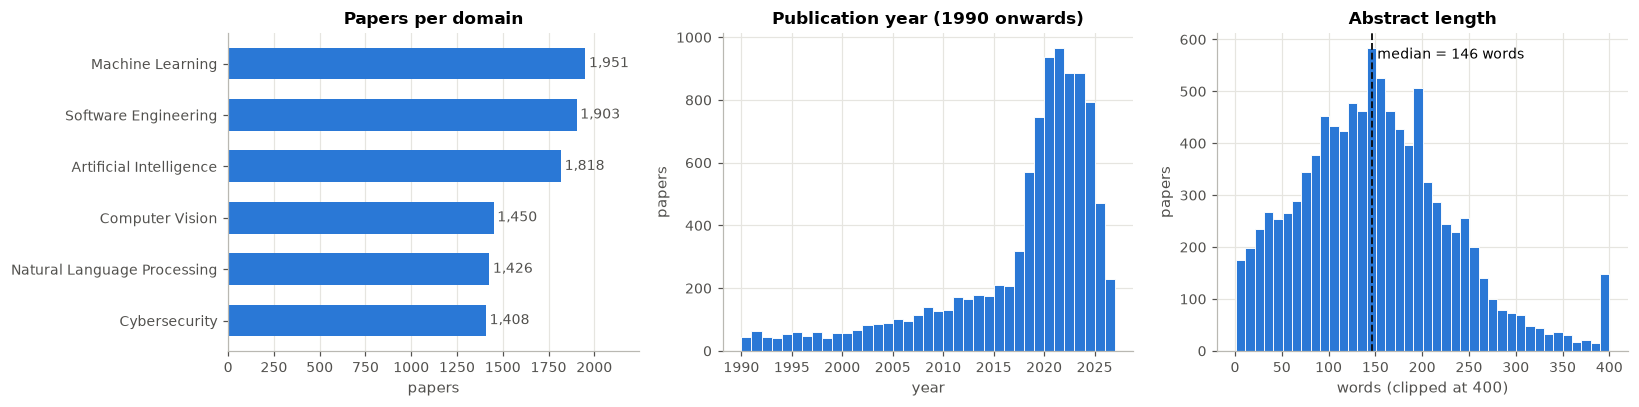

Domains: Machine Learning, Software Engineering, Artificial Intelligence, Computer Vision, Natural Language Processing, Cybersecurity


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

dc = df["domain"].value_counts().sort_values()
ax[0].barh(dc.index, dc.values, color=BLUE, height=0.62)
for y, v in enumerate(dc.values):
    ax[0].text(v + 20, y, f"{v:,}", va="center", fontsize=9, color="#52514e")
ax[0].set_title("Papers per domain"); ax[0].set_xlabel("papers"); ax[0].grid(axis="y", visible=False)
ax[0].set_xlim(0, dc.max() * 1.15)

yr = df["year"].dropna(); yr = yr[(yr >= 1990) & (yr <= 2026)]
ax[1].hist(yr, bins=np.arange(1990, 2028), color=BLUE, edgecolor="white", linewidth=0.6)
ax[1].set_title("Publication year (1990 onwards)"); ax[1].set_xlabel("year"); ax[1].set_ylabel("papers")

alen = df["abstract"].str.split().apply(len)
ax[2].hist(alen.clip(upper=400), bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
ax[2].axvline(alen.median(), color="#0b0b0b", lw=1.2, ls="--")
ax[2].text(alen.median() + 6, ax[2].get_ylim()[1] * 0.92, f"median = {int(alen.median())} words", fontsize=9)
ax[2].set_title("Abstract length"); ax[2].set_xlabel("words (clipped at 400)"); ax[2].set_ylabel("papers")

plt.tight_layout(); plt.show()
print("Domains:", ", ".join(dc.index[::-1]))

## 2. Text preprocessing  *(Objective 1)*

Raw text is noisy: "Learning", "learned" and "learns" are three different strings but one concept. The standard NLP
pipeline turns each document into a clean list of *terms*:

| Step | Example | Why |
|---|---|---|
| lower-casing | `Deep Learning` → `deep learning` | case carries no topical meaning |
| tokenisation (letters only) | `GPT-4, 2023!` → `gpt` | removes punctuation and digits |
| stop-word removal | drop `the, of, and, is…` | these appear everywhere and discriminate nothing |
| drop tokens of length ≤ 2 | drop `we`, `an` | mostly noise |
| **Porter stemming** | `learning, learned, learns` → `learn` | merges morphological variants into **one dimension** |

**What the code does** — `preprocess(text)` applies exactly these five steps and returns the cleaned string; it is
mapped over all papers and a before/after example is printed. The same function is reused later for free-text
queries, so documents and queries live in the same vocabulary.

In [4]:
stemmer = PorterStemmer()
_token  = re.compile(r"[a-z]+")            # a token = a run of letters (drops punctuation and digits)
_stop   = set(ENGLISH_STOP_WORDS)          # scikit-learn's English stop-word list

def preprocess(text: str) -> str:
    '''lowercase -> tokenise -> remove stop-words / short tokens -> Porter stemming.'''
    return " ".join(stemmer.stem(w) for w in _token.findall(str(text).lower())
                    if w not in _stop and len(w) > 2)

t0 = time.time()
df["clean"] = df["text"].map(preprocess)
print("Preprocessed %d documents in %.1fs" % (N, time.time() - t0))
print("\nBEFORE:", df["text"].iloc[0][:140], "...")
print("AFTER :", df["clean"].iloc[0][:140], "...")

Preprocessed 9956 documents in 6.3s

BEFORE: Machine learning and deep learning. Abstract Today, intelligent systems that offer artificial intelligence capabilities often rely on machin ...
AFTER : machin learn deep learn abstract today intellig system offer artifici intellig capabl reli machin learn machin learn describ capac system le ...


## 3. The mathematics, first on a toy corpus  *(Objectives 2 and 4)*

Before touching 10,000 papers, here is the entire idea on eight tiny documents, small enough to check by hand.

**Term–document matrix.** With $m$ documents and $n$ distinct terms, $C \in \mathbb{R}^{m \times n}$ has
$C_{ij}$ = number of times term $j$ occurs in document $i$. Every document is a row vector in $\mathbb{R}^n$.

**Cosine similarity.** $\cos(x, y) = \dfrac{x \cdot y}{\lVert x\rVert\,\lVert y\rVert}$. It is 1 for parallel vectors and 0
for orthogonal ones — and two documents that **share no word are orthogonal**, however related they are.

**SVD.** Every real matrix factorises as $C = U \Sigma V^{\mathsf T}$ with $U^{\mathsf T}U = I$, $V^{\mathsf T}V = I$ and
$\Sigma = \operatorname{diag}(\sigma_1 \ge \sigma_2 \ge \dots \ge 0)$. Because
$C^{\mathsf T} C = V \Sigma^2 V^{\mathsf T}$, the right singular vectors $V$ are the **eigenvectors of the symmetric matrix
$C^{\mathsf T}C$** and the singular values are the square roots of its eigenvalues; then $U = C V \Sigma^{-1}$.

**Eckart–Young theorem.** Keeping only the $k$ largest singular values, $C_k = U_k \Sigma_k V_k^{\mathsf T}$, is the *best
possible* rank-$k$ approximation of $C$, and the error is exactly the discarded energy:
$\lVert C - C_k \rVert_F^2 = \sum_{i>k} \sigma_i^2$.

**What the code does**

1. Builds the count matrix for 8 mini-documents (5 about vehicles, 3 about plants).
2. Computes the SVD **by hand** from the eigen-decomposition of $C^{\mathsf T}C$ and checks it against `np.linalg.svd`.
3. Verifies orthonormality and the Eckart–Young identity numerically.
4. Compares cosine similarities in the original space and in the rank-2 latent space.

In [5]:
toy_docs = ["car engine", "automobile engine", "car wheel", "automobile wheel", "engine wheel",
            "flower garden", "rose garden", "flower rose"]
toy_terms = sorted({w for d in toy_docs for w in d.split()})
C = np.array([[d.split().count(t) for t in toy_terms] for d in toy_docs], dtype=float)   # 8 docs x 7 terms
print("Term-document matrix C (rows = documents, columns = terms):")
display(pd.DataFrame(C.astype(int), index=[f"d{i+1}: {d}" for i, d in enumerate(toy_docs)], columns=toy_terms))

# ---- SVD "by hand": eigen-decomposition of the symmetric matrix C^T C --------------------------
evals, V = np.linalg.eigh(C.T @ C)                 # eigh returns eigenvalues in ascending order
order = np.argsort(evals)[::-1]                    # sort descending
evals, V = evals[order], V[:, order]
sigma = np.sqrt(np.clip(evals, 0, None))           # singular values = sqrt(eigenvalues)
rank = int((sigma > 1e-10).sum())
U = (C @ V[:, :rank]) / sigma[:rank]               # U = C V Sigma^{-1}

print("Singular values (by hand)      :", sigma.round(4))
print("Singular values (np.linalg.svd):", np.linalg.svd(C, compute_uv=False).round(4))
print("rank(C) =", rank)
print("U^T U = I ?", np.allclose(U.T @ U, np.eye(rank)), "   V^T V = I ?", np.allclose(V.T @ V, np.eye(len(toy_terms))))
print("C = U S V^T ?", np.allclose(C, (U * sigma[:rank]) @ V[:, :rank].T))

# ---- rank-2 truncation and the Eckart-Young identity -------------------------------------------
k = 2
C_k = (U[:, :k] * sigma[:k]) @ V[:, :k].T
print("\nEckart-Young:  ||C - C_2||_F^2 = %.4f    sum of discarded sigma_i^2 = %.4f"
      % (np.linalg.norm(C - C_k, "fro") ** 2, (sigma[k:] ** 2).sum()))

# ---- cosine similarity before and after ---------------------------------------------------------
Z_toy = U[:, :k] * sigma[:k]                        # each document as a 2-D latent vector
cos = lambda X: normalize(X) @ normalize(X).T
pairs = [(0, 3, "d1 'car engine'  vs  d4 'automobile wheel'  (related, no shared word)"),
         (0, 5, "d1 'car engine'  vs  d6 'flower garden'     (unrelated)")]
print()
for i, j, label in pairs:
    print("%-70s  raw cosine = %.3f   rank-2 cosine = %.3f" % (label, cos(C)[i, j], cos(Z_toy)[i, j]))

Term-document matrix C (rows = documents, columns = terms):


,automobile,car,engine,flower,garden,rose,wheel
d1: car engine,0,1,1,0,0,0,0
d2: automobile engine,1,0,1,0,0,0,0
d3: car wheel,0,1,0,0,0,0,1
d4: automobile wheel,1,0,0,0,0,0,1
d5: engine wheel,0,0,1,0,0,0,1
d6: flower garden,0,0,0,1,1,0,0
d7: rose garden,0,0,0,0,1,1,0
d8: flower rose,0,0,0,1,0,1,0


Singular values (by hand)      : [2.2882 2.     1.4142 1.4142 1.     1.     0.874 ]
Singular values (np.linalg.svd): [2.2882 2.     1.4142 1.4142 1.     1.     0.874 ]
rank(C) = 7
U^T U = I ? True    V^T V = I ? True
C = U S V^T ? True

Eckart-Young:  ||C - C_2||_F^2 = 6.7639    sum of discarded sigma_i^2 = 6.7639

d1 'car engine'  vs  d4 'automobile wheel'  (related, no shared word)   raw cosine = 0.000   rank-2 cosine = 1.000
d1 'car engine'  vs  d6 'flower garden'     (unrelated)                 raw cosine = 0.000   rank-2 cosine = -0.000


**Reading the output.** In the original space *"car engine"* and *"automobile wheel"* have cosine **0** because they share
no word — the vector-space model cannot see that both are about vehicles. After the rank-2 truncation their cosine is
close to **1**, while the vehicle-vs-plant pair stays near **0**. The two retained singular directions are the two
*concepts* in the corpus ("vehicles" and "plants"); words that co-occur (car ↔ engine ↔ automobile) are pulled onto the
same direction. That is **Latent Semantic Analysis**, and it is exactly what Approach B does at scale.

## 4. TF-IDF term–document matrix  *(Objective 2)*

Raw counts over-reward long documents and common words, so each entry is re-weighted. For term $j$ in document $i$,
with $m$ documents in total and $\mathrm{df}(j)$ documents containing term $j$, the exact formula implemented by the
settings below is

$$
w_{ij} \;=\; \underbrace{\bigl(1 + \ln \mathrm{tf}_{ij}\bigr)}_{\text{sub-linear term frequency}}
\times \underbrace{\Bigl(\ln\frac{1+m}{1+\mathrm{df}(j)} + 1\Bigr)}_{\text{smoothed inverse document frequency}},
\qquad\text{then each row is scaled to unit length: } a_i = \frac{w_i}{\lVert w_i \rVert_2}.
$$

- **TF** rewards terms that are frequent *in this paper* (logarithm: the 10th occurrence matters less than the 1st).
- **IDF** rewards terms that are rare *across the corpus* — these are the terms that characterise a paper.
- **Unit-length rows** make the cosine similarity of two papers simply their dot product: $\cos(a_i, a_j) = a_i \cdot a_j$.

Stacking the rows gives $A \in \mathbb{R}^{m \times n}$ with $m$ = papers and $n$ = terms. $A$ is extremely **sparse**
(a paper uses only ~100 of the ~31,000 terms), so it is stored in compressed sparse row format.

**What the code does** — configures and fits the vectoriser (`min_df=5` drops terms seen in fewer than 5 papers;
`max_df=0.5` drops terms seen in more than half the papers; `ngram_range=(1,2)` keeps single words and two-word
phrases such as *"neural network"*), then reports the matrix shape and sparsity and confirms that the rows are unit
vectors. This configuration is unchanged from the intermediate submission — §9 shows it was already near-optimal.

In [6]:
vectorizer = TfidfVectorizer(
    min_df=5,             # ignore terms that occur in fewer than 5 papers (typos, noise)
    max_df=0.5,           # ignore terms that occur in more than 50% of papers (carry no information)
    ngram_range=(1, 2),   # unigrams and bigrams
    sublinear_tf=True,    # tf -> 1 + ln(tf)
)                         # norm="l2" is the default: every row is scaled to unit length
t0 = time.time()
A = vectorizer.fit_transform(df["clean"]).tocsr()     # sparse term-document matrix, shape (m, n)
build_time_tfidf = time.time() - t0
A_T = A.T.tocsr()                                     # transpose, kept in CSR form for fast products
terms = vectorizer.get_feature_names_out()

m, n = A.shape
row_norms = np.sqrt(A.multiply(A).sum(axis=1)).A1
print("Term-document matrix A in R^(m x n)")
print("  m = %d documents,  n = %d terms" % (m, n))
print("  non-zeros: %d  (%.3f%% of the %d x %d entries)" % (A.nnz, 100 * A.nnz / (m * n), m, n))
print("  average distinct terms per paper: %.0f" % (A.nnz / m))
print("  rows are unit vectors: min norm %.6f, max norm %.6f" % (row_norms.min(), row_norms.max()))
print("  build time: %.2fs" % build_time_tfidf)

Term-document matrix A in R^(m x n)
  m = 9956 documents,  n = 31291 terms
  non-zeros: 958997  (0.308% of the 9956 x 31291 entries)
  average distinct terms per paper: 96
  rows are unit vectors: min norm 1.000000, max norm 1.000000
  build time: 0.73s


## 5. Approach A — baseline: TF-IDF + cosine similarity  *(Objective 3)*

Because every row of $A$ has unit length, the similarity of a query paper $a_q$ to **all** papers at once is one sparse
matrix–vector product:

$$ s = A\,a_q^{\mathsf T} \in \mathbb{R}^{m}, \qquad s_i = \cos(a_i, a_q). $$

Recommending is then just "take the $K$ largest entries of $s$ (excluding the query itself)".

**What the code does** — `recommend_tfidf(idx, k)` computes $s$, masks the query paper, uses `argpartition` to find
the top-$k$ in linear time, sorts those $k$, and returns them as a small table. It is demonstrated on a seed paper.

In [7]:
def top_k(sims, k):
    '''Indices of the k largest scores, best first (argpartition is O(m), then only k items are sorted).'''
    top = np.argpartition(-sims, k)[:k]
    return top[np.argsort(-sims[top])]

def result_table(sims, top, cols=("title", "domain", "year")):
    out = df.loc[top, list(cols)].copy()
    out.insert(0, "similarity", np.round(sims[top], 3))
    return out.reset_index(drop=True)

def recommend_tfidf(idx, k=5):
    '''Top-k papers most similar to paper `idx` in the full TF-IDF space (Approach A).'''
    sims = (A @ A[idx].T).toarray().ravel()     # s = A a_q^T  -> cosine similarity to every paper
    sims[idx] = -np.inf                          # never recommend the query paper itself
    return result_table(sims, top_k(sims, k))

seed = int(df.index[df["title"].str.contains("deep learning", case=False, na=False)][0])
print("QUERY PAPER:", df["title"].iloc[seed], "\n")
recommend_tfidf(seed, 5)

QUERY PAPER: Machine learning and deep learning 



,similarity,title,domain,year
0,0.175,Learning machine learning,Machine Learning,2018.0
1,0.148,"Machine learning, artificial intelligence and the prediction of dementia",Machine Learning,2021.0
2,0.148,COMPUTER VISION FOR HUMAN-MACHINE INTERACTION-REVIEW,Computer Vision,2019.0
3,0.147,Neural Networks in Cybersecurity,Cybersecurity,2023.0
4,0.145,Research on the Application of Deep Learning in Natural Language Processing,Natural Language Processing,2024.0


## 6. Dimensionality reduction with SVD  *(Objective 4)*

### 6.1 Theory

$$A = U \Sigma V^{\mathsf T}, \qquad A_k = U_k \Sigma_k V_k^{\mathsf T} \ \text{(best rank-}k\text{ approximation, Eckart–Young)}.$$

- Columns of $V_k \in \mathbb{R}^{n \times k}$ are orthonormal **term directions** ("concepts").
- Each paper is represented by its row of $Z_k = U_k \Sigma_k = A V_k \in \mathbb{R}^{m \times k}$ — its coordinates
  along the $k$ concepts. This is a **projection** of the 31,000-dimensional row onto a $k$-dimensional subspace.
- **Why cosine in the small space is meaningful:** $Z_k Z_k^{\mathsf T} = U_k\Sigma_k^2U_k^{\mathsf T} = A_k A_k^{\mathsf T}$.
  Dot products between latent vectors are *exactly* the dot products between the rank-$k$ reconstructed documents — we
  get the de-noised similarities without ever forming the dense $m \times n$ matrix $A_k$.
- **A new query** $q \in \mathbb{R}^n$ is "folded in" with the same projection: $z_q = q\,V_k$.
- **Nestedness:** the rank-$k$ factors are the first $k$ columns of any larger-rank SVD, so we factorise **once** at
  $k_{\max}=1000$ and slice out every smaller $k$.

### 6.2 Computation

A full SVD of a $9956 \times 31291$ matrix is wasteful when only the leading part is needed. `TruncatedSVD` uses the
**randomised SVD** algorithm (Halko, Martinsson and Tropp, 2011): multiply $A$ by a random matrix to capture its
dominant column space, sharpen it with a few power iterations $(AA^{\mathsf T})^p A\,\Omega$, orthonormalise (QR), and
take an exact SVD of the small projected matrix. It only needs sparse products $A x$ and $A^{\mathsf T} y$.

**What the code does** — fits one rank-1000 randomised SVD, then for each $k$ stores the row-normalised latent
matrix (so cosine = dot product, as before) as `float32`.

In [8]:
K_MAX    = 1000
K_VALUES = [50, 100, 200, 300, 500, 1000]

t0 = time.time()
svd = TruncatedSVD(n_components=K_MAX, n_iter=7, random_state=SEED)
Z = svd.fit_transform(A)                    # Z = U_k Sigma_k = A V_k,  shape (m, 1000)
svd_fit_time = time.time() - t0
sigma = svd.singular_values_                # sigma_1 >= sigma_2 >= ...
Vt = svd.components_                        # V_k^T, shape (1000, n): rows are the right singular vectors

# Row-normalised latent vectors for every k (first k columns of Z), ready for cosine = dot product.
Zn = {k: normalize(Z[:, :k]).astype(np.float32) for k in K_VALUES}

print("Randomised SVD with k_max = %d computed in %.1fs" % (K_MAX, svd_fit_time))
print("Z shape:", Z.shape, "  V^T shape:", Vt.shape)
print("Largest singular values:", sigma[:6].round(3))

Randomised SVD with k_max = 1000 computed in 13.9s
Z shape: (9956, 1000)   V^T shape: (1000, 31291)
Largest singular values: [16.231  8.497  8.252  7.666  7.21   6.711]


### 6.3 Verifying the factorisation numerically

A computed factorisation should be *checked*, not trusted. Each line below tests one property stated in §6.1:

1. **Orthonormality** — $V_k^{\mathsf T}V_k = I$.
2. **Projection** — $Z = A V_k$ (the latent vectors really are projections of the TF-IDF rows; scikit-learn builds $Z$ this way, so this check should be exactly zero).
3. **Accuracy of the randomised algorithm** — the top singular values agree with ARPACK (`scipy.sparse.linalg.svds`),
   an independent iterative solver.
4. **Pythagoras / Eckart–Young, row by row** — since $z_i$ is an orthogonal projection of $a_i$,
   $\lVert a_i - a_i V_k V_k^{\mathsf T} \rVert^2 = \lVert a_i\rVert^2 - \lVert z_i \rVert^2$. Checked by explicitly reconstructing 300 rows.
5. **Energy** — because the rows are unit vectors, $\lVert A \rVert_F^2 = m$, so the fraction of the matrix's energy kept by
   rank $k$ is $\sum_{i \le k} \sigma_i^2 / m$.
6. **Gram identity** — $Z_k Z_k^{\mathsf T} = A_k A_k^{\mathsf T}$ on a sample of rows.

In [9]:
rng_chk = np.random.default_rng(SEED)

# 1. orthonormal right singular vectors
print("1. max |V^T V - I|                       = %.2e" % np.abs(Vt @ Vt.T - np.eye(K_MAX)).max())

# 2. Z = A V
print("2. max |Z - A V|                         = %.2e" % np.abs(Z - A @ Vt.T).max())

# 3. randomised SVD vs ARPACK on the 10 largest singular values
s_arpack = np.sort(svds(A, k=10, return_singular_vectors=False))[::-1]
print("3. max relative error of top-10 sigma    = %.2e" % (np.abs(sigma[:10] - s_arpack) / s_arpack).max())

# 4. Pythagoras on 300 explicitly reconstructed rows, k = 300
k = 300
rows = rng_chk.choice(m, 300, replace=False)
A_rows   = A[rows].toarray()
A_k_rows = Z[rows, :k] @ Vt[:k]                                   # rows of the rank-k approximation A_k
lhs = ((A_rows - A_k_rows) ** 2).sum(axis=1)                      # ||a_i - a_i V_k V_k^T||^2
rhs = 1.0 - (Z[rows, :k] ** 2).sum(axis=1)                        # ||a_i||^2 - ||z_i||^2   (||a_i|| = 1)
print("4. max |residual^2 - (1 - ||z_i||^2)|    = %.2e   (k = %d)" % (np.abs(lhs - rhs).max(), k))

# 5. energy retained:  ||A||_F^2 = m  because every row has unit norm
fro2 = A.multiply(A).sum()
print("5. ||A||_F^2 = %.1f (m = %d).  Energy kept by rank k:" % (fro2, m),
      ",  ".join("k=%d: %.1f%%" % (k, 100 * (sigma[:k] ** 2).sum() / fro2) for k in K_VALUES))

# 6. Gram identity  Z_k Z_k^T = A_k A_k^T
print("6. max |Z_k Z_k^T - A_k A_k^T|           = %.2e" %
      np.abs(Z[rows, :k] @ Z[rows, :k].T - A_k_rows @ A_k_rows.T).max())

1. max |V^T V - I|                       = 1.65e-14


2. max |Z - A V|                         = 0.00e+00
3. max relative error of top-10 sigma    = 2.58e-15
4. max |residual^2 - (1 - ||z_i||^2)|    = 2.00e-15   (k = 300)
5. ||A||_F^2 = 9956.0 (m = 9956).  Energy kept by rank k: k=50: 11.3%,  k=100: 14.9%,  k=200: 20.5%,  k=300: 25.0%,  k=500: 32.2%,  k=1000: 44.7%
6. max |Z_k Z_k^T - A_k A_k^T|           = 6.77e-15


All six residuals are at the level of floating-point round-off, so the computed factors behave exactly as the theory
says (check 3 also shows that, with 7 power iterations, the randomised algorithm reproduces the leading singular
values of an independent solver to machine precision).

Note the energy figures: even 1000 dimensions keep well under half of $\lVert A \rVert_F^2$. TF-IDF matrices have a
long, slowly-decaying spectrum — most of that "energy" is paper-specific word noise, which is precisely what we *want*
to discard. Retrieval quality (§9), not reconstruction error, is the right way to choose $k$.

### 6.4 Singular-value spectrum

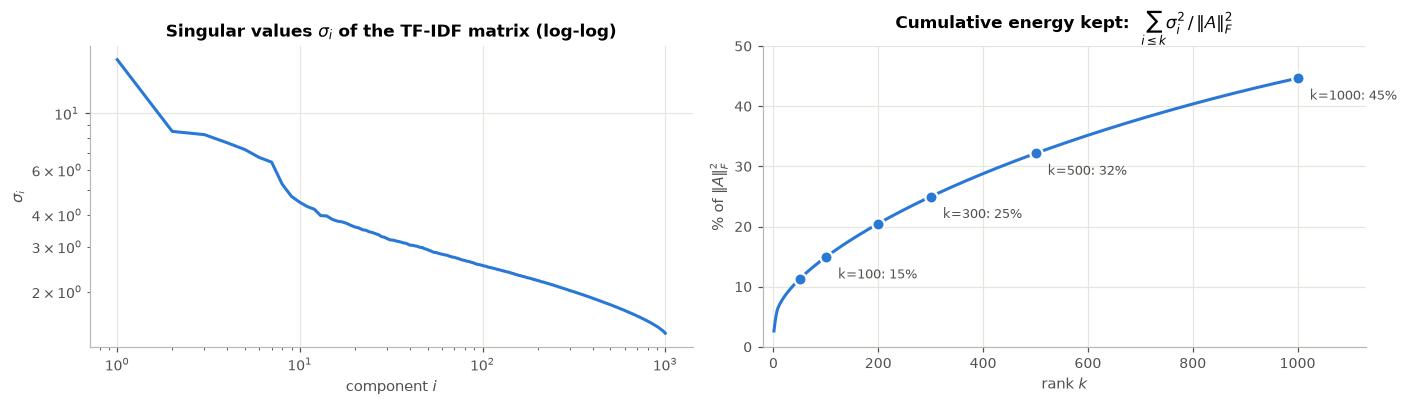

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(np.arange(1, K_MAX + 1), sigma, color=BLUE)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_title("Singular values $\\sigma_i$ of the TF-IDF matrix (log-log)")
ax[0].set_xlabel("component $i$"); ax[0].set_ylabel("$\\sigma_i$")

energy = 100 * np.cumsum(sigma ** 2) / fro2
ax[1].plot(np.arange(1, K_MAX + 1), energy, color=BLUE)
for k in K_VALUES:
    ax[1].plot(k, energy[k - 1], "o", color=BLUE, markeredgecolor="white", markeredgewidth=1.5, markersize=8)
for k in [100, 300, 500, 1000]:                      # label a readable subset; all values are printed in check 5
    ax[1].annotate("k=%d: %.0f%%" % (k, energy[k - 1]), (k, energy[k - 1]), textcoords="offset points",
                   xytext=(8, -14), fontsize=8.5, color="#52514e")
ax[1].set_title("Cumulative energy kept:  $\\sum_{i\\leq k}\\sigma_i^2 \\,/\\, \\|A\\|_F^2$")
ax[1].set_xlabel("rank $k$"); ax[1].set_ylabel("% of $\\|A\\|_F^2$"); ax[1].set_ylim(0, energy[-1] * 1.12); ax[1].set_xlim(-20, 1130)
plt.tight_layout(); plt.show()

### 6.5 What do the latent dimensions mean?

Each right singular vector $v_i$ (a row of $V^{\mathsf T}$) assigns a weight to every term. Listing the terms with the
largest positive and negative weights shows the "concept" that dimension separates. The first vector is the
corpus-wide average direction; from the second onwards the vectors **contrast** research areas.

**What the code does** — for the first six singular vectors, prints the eight strongest terms on each side
(terms are stems, e.g. `secur` = security).

In [11]:
for i in range(6):
    v = Vt[i]
    pos = ", ".join(terms[np.argsort(-v)[:8]])
    neg = ", ".join(terms[np.argsort(v)[:8]])
    print("v%d  (sigma = %.2f)" % (i + 1, sigma[i]))
    print("    + : %s" % pos)
    if i > 0:
        print("    - : %s" % neg)

v1  (sigma = 16.23)
    + : learn, machin, comput, machin learn, intellig, process, artifici, artifici intellig
v2  (sigma = 8.50)
    + : softwar, engin, softwar engin, program, softwar develop, manag, cybersecur, develop
    - : learn, machin, machin learn, natur languag, languag process, natur, languag, nlp
v3  (sigma = 8.25)
    + : languag, natur languag, languag process, natur, process, nlp, softwar, process nlp
    - : cybersecur, machin learn, artifici, artifici intellig, intellig, vision, comput vision, learn
v4  (sigma = 7.67)
    + : cybersecur, artifici intellig, intellig, artifici, secur, cyber, threat, risk
    - : vision, comput vision, comput, imag, softwar, engin, softwar engin, learn
v5  (sigma = 7.21)
    + : vision, comput vision, cybersecur, comput, secur, cyber, imag, threat
    - : machin learn, machin, learn, softwar, engin, softwar engin, artifici, artifici intellig
v6  (sigma = 6.71)
    + : artifici intellig, intellig, artifici, vision, comput vision, comput,

## 7. Approach B — recommendation in the reduced space  *(Objective 5)*

Identical logic to Approach A, but on the dense $k$-dimensional latent vectors: $s = \hat Z_k\,\hat z_q$ where
$\hat Z_k$ is the row-normalised latent matrix. The product costs $m \cdot k$ multiplications instead of a sparse
product over 31,000 columns.

**What the code does** — `recommend_svd(idx, k_dim, k)` mirrors `recommend_tfidf`. Note how the similarity scores are
much higher than in §5: after removing word-level noise, topically related papers really do point in nearly the same
direction.

In [12]:
def recommend_svd(idx, k_dim=300, k=5):
    '''Top-k papers most similar to paper `idx` in the rank-k_dim SVD space (Approach B).'''
    V_ = Zn[k_dim]
    sims = V_ @ V_[idx]                      # cosine similarity in the latent space
    sims[idx] = -np.inf
    return result_table(sims, top_k(sims, k))

print("QUERY PAPER:", df["title"].iloc[seed], "  (SVD, k = 300)\n")
recommend_svd(seed, 300, 5)

QUERY PAPER: Machine learning and deep learning   (SVD, k = 300)



,similarity,title,domain,year
0,0.525,"Machine learning, artificial intelligence and the prediction of dementia",Machine Learning,2021.0
1,0.522,Machine Learning and Deep Learning Applications-A Vision,Machine Learning,2021.0
2,0.507,Clinical applications of continual learning machine learning,Machine Learning,2020.0
3,0.504,"Trends in artificial intelligence, machine learning, and chemometrics applied to chemi...",Machine Learning,2021.0
4,0.501,"Artificial intelligence, machine learning, and deep learning in women’s health nursing",Machine Learning,2020.0


## 8. Evaluation framework  *(Objective 6)*

### 8.1 Ground truth
There are no human relevance judgements, so relevance is derived from OpenAlex's `topics` field: **two papers are
relevant to each other if they share at least one of their three topics.** With the binary paper–topic incidence
matrix $T \in \{0,1\}^{m \times 1846}$, the relevance matrix is simply $R = [\,T T^{\mathsf T} > 0\,]$ — entry $(i,j)$ counts
shared topics.

### 8.2 Metrics (per query, then averaged)
For a query with ranked recommendations $d_1, d_2, \dots$ and relevance indicators $\mathrm{rel}_i \in \{0,1\}$:

| Metric | Formula | Meaning |
|---|---|---|
| **Precision@K** | $\frac1K\sum_{i=1}^{K}\mathrm{rel}_i$ | fraction of the top-$K$ that is relevant |
| **Recall@K** | $\frac{1}{\#\text{relevant}}\sum_{i=1}^{K}\mathrm{rel}_i$ | fraction of all relevant papers that was retrieved |
| **MRR** | $1/\text{rank of first relevant result}$ (0 if none in the top 10) | how soon the first good result appears |
| **nDCG@10** | $\dfrac{\sum_{i=1}^{10}\mathrm{rel}_i/\log_2(i+1)}{\text{best achievable value}}$ | like precision, but rewards putting relevant papers *higher* |
| **P@1** | $\mathrm{rel}_1$ | is the single best recommendation relevant? |
| **Hit@10** | $\max_{i \le 10} \mathrm{rel}_i$ | does the top 10 contain *at least one* relevant paper? |

### 8.3 Protocol — what changed since the intermediate report, and why

| | Intermediate report | Final submission |
|---|---|---|
| Queries | 400 random papers | **every** paper that has at least one relevant paper (≈9,900) |
| Tuning vs reporting | same queries for both | **validation** queries (3,000) to choose settings, **test** queries (≈6,900) to report |
| Uncertainty | none | bootstrap 95% confidence intervals + paired significance tests |
| Ranking metric | P@K, R@K, MRR | + **nDCG@10** |
| Context | none | + random-ranking baseline |

Choosing a hyper-parameter and reporting the score on the same queries gives optimistically biased numbers; the
validation/test split removes that bias. Using all queries instead of 400 shrinks the confidence intervals about
four-fold.

**What the code does**

- Builds $T$ and the dense boolean relevance matrix `REL` (≈100 MB), removing the diagonal (a paper is not its own recommendation).
- Splits the usable queries into `VAL` and `TEST`.
- `evaluate(sim_fn, queries)` — the single evaluation routine used for **every** method. `sim_fn(q)` must return the
  similarity of each query in `q` to all $m$ papers; the routine masks the query itself, extracts the top 10, and
  returns one row of seven metrics per query (so that confidence intervals and paired tests can be computed later).

In [13]:
# ---- topic incidence matrix T (papers x topics) and relevance matrix REL = [T T^T > 0] ------------
topic_lists = df["topics"].fillna("").map(lambda s: [t.strip().lower() for t in s.split(";") if t.strip()])
topic_names = np.array(sorted({t for ts in topic_lists for t in ts}))
topic_id = {t: i for i, t in enumerate(topic_names)}
rows_, cols_ = zip(*[(i, topic_id[t]) for i, ts in enumerate(topic_lists) for t in ts])
T = sp.csr_matrix((np.ones(len(rows_), dtype=np.float32), (rows_, cols_)), shape=(N, len(topic_names)))

REL = (T @ T.T).toarray() > 0            # REL[i, j] = True  <=>  papers i and j share >= 1 topic
np.fill_diagonal(REL, False)
N_REL = REL.sum(axis=1)                  # number of relevant papers for each query

# ---- validation / test split of the query papers ---------------------------------------------------
usable = np.where(N_REL > 0)[0]
perm = np.random.default_rng(SEED).permutation(usable)
VAL, TEST = np.sort(perm[:3000]), np.sort(perm[3000:])

print("Distinct topics: %d" % len(topic_names))
print("Papers with topics: %d   |   usable query papers: %d" % (int((T.sum(axis=1) > 0).sum()), len(usable)))
print("Validation queries: %d   |   Test queries: %d" % (len(VAL), len(TEST)))
print("Relevant papers per query: median %d, mean %.0f" % (np.median(N_REL[usable]), N_REL[usable].mean()))
print("Expected Precision of a RANDOM ranking = mean(#relevant / (m-1)) = %.4f" % (N_REL[TEST] / (N - 1)).mean())

Distinct topics: 1846
Papers with topics: 9917   |   usable query papers: 9911
Validation queries: 3000   |   Test queries: 6911
Relevant papers per query: median 819, mean 749
Expected Precision of a RANDOM ranking = mean(#relevant / (m-1)) = 0.0753


In [14]:
METRICS = ["P@5", "P@10", "R@10", "MRR", "nDCG@10", "P@1", "Hit@10"]
DISCOUNT = 1.0 / np.log2(np.arange(2, 12))                               # 1/log2(i+1) for ranks i = 1..10
IDEAL_DCG = np.array([DISCOUNT[:min(10, r)].sum() for r in N_REL])       # DCG of a perfect top-10

def evaluate(sim_fn, queries, chunk=500):
    '''Evaluate a similarity function.
       sim_fn(q) -> array (len(q), m): similarity of each query paper in q to every paper.
       Returns an array (len(queries), 7) with P@5, P@10, R@10, RR, nDCG@10, P@1 and Hit@10 for every query.'''
    out = []
    for s in range(0, len(queries), chunk):                              # process queries in chunks (memory)
        q = queries[s:s + chunk]
        S = np.asarray(sim_fn(q), dtype=np.float32)
        S[np.arange(len(q)), q] = -np.inf                                # a paper must not recommend itself
        top = np.argpartition(-S, 10, axis=1)[:, :10]                    # the 10 best per row (unordered)
        order = np.argsort(-np.take_along_axis(S, top, axis=1), axis=1)
        top = np.take_along_axis(top, order, axis=1)                     # ... now ordered best-first
        hit = REL[q[:, None], top]                                       # hit[i, j] = is the j-th result relevant?
        rr = np.where(hit.any(axis=1), 1.0 / (hit.argmax(axis=1) + 1), 0.0)
        out.append(np.c_[hit[:, :5].mean(axis=1),                        # P@5
                         hit.mean(axis=1),                               # P@10
                         hit.sum(axis=1) / N_REL[q],                     # R@10
                         rr,                                             # reciprocal rank
                         (hit * DISCOUNT).sum(axis=1) / IDEAL_DCG[q],    # nDCG@10
                         hit[:, 0],                                      # P@1: is the first result relevant?
                         hit.any(axis=1)])                               # Hit@10: any relevant result in the top 10?
    return np.vstack(out)

def summary(scores):
    return dict(zip(METRICS, scores.mean(axis=0)))

# ---- similarity functions for the unsupervised approaches -----------------------------------------
def sim_tfidf(q):                      # Approach A
    return (A[q] @ A_T).toarray()

def sim_svd(k):                        # Approach B
    V_ = Zn[k]
    return lambda q: V_[q] @ V_.T

def sim_hybrid(k, alpha):              # Approach B+ : alpha * TF-IDF cosine + (1 - alpha) * SVD cosine
    f = sim_svd(k)
    return lambda q: alpha * sim_tfidf(q) + (1 - alpha) * f(q)

## 9. Tuning the unsupervised approaches on the validation queries

Three questions are answered here, using **validation queries only**:

1. **Is the TF-IDF configuration a good baseline?** A weak baseline would make every other method look good, so a few
   alternative vectoriser settings are tried.
2. **How does SVD quality change with $k$?**
3. **Does combining A and B help (B+)?** TF-IDF matches exact words; SVD matches concepts. Their errors differ, so a
   weighted sum $\alpha\,s_{\text{TF-IDF}} + (1-\alpha)\,s_{\text{SVD}}$ can beat both.

**What the code does** — runs `evaluate` on `VAL` for each setting and collects the mean metrics in tables. The
hybrid's $(k, \alpha)$ is chosen by validation nDCG@10.

In [15]:
# ---- 1. is the baseline configuration reasonable? --------------------------------------------------
variants = {
    "chosen: min_df=5, max_df=0.5, 1-2 grams, sublinear tf": dict(min_df=5, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True),
    "unigrams only":                                         dict(min_df=5, max_df=0.5, ngram_range=(1, 1), sublinear_tf=True),
    "1-3 grams":                                             dict(min_df=5, max_df=0.5, ngram_range=(1, 3), sublinear_tf=True),
    "raw term frequency (no log)":                           dict(min_df=5, max_df=0.5, ngram_range=(1, 2), sublinear_tf=False),
    "min_df=2 (bigger vocabulary)":                          dict(min_df=2, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True),
    "max_df=0.2 (drop more common terms)":                   dict(min_df=5, max_df=0.2, ngram_range=(1, 2), sublinear_tf=True),
}
rows = []
for name, kw in variants.items():
    X = TfidfVectorizer(**kw).fit_transform(df["clean"]).tocsr(); X_T = X.T.tocsr()
    r = summary(evaluate(lambda q: (X[q] @ X_T).toarray(), VAL)); r.update(setting=name, terms=X.shape[1]); rows.append(r)
val_tfidf = pd.DataFrame(rows).set_index("setting")[["terms"] + METRICS]
print("TF-IDF configurations (validation queries)")
display(val_tfidf.round(4))

TF-IDF configurations (validation queries)


,terms,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
setting,,,,,,,,
"chosen: min_df=5, max_df=0.5, 1-2 grams, sublinear tf",31291,0.7365,0.6975,0.0292,0.8604,0.7181,0.7903,0.9710
unigrams only,5726,0.7419,0.7025,0.0294,0.8687,0.7241,0.8050,0.9703
1-3 grams,36564,0.7115,0.6775,0.0276,0.8426,0.6971,0.7660,0.9673
raw term frequency (no log),31291,0.7138,0.6765,0.0278,0.8410,0.6965,0.7700,0.9607
min_df=2 (bigger vocabulary),119792,0.7364,0.6960,0.0298,0.8668,0.7186,0.8000,0.9730
max_df=0.2 (drop more common terms),31254,0.7152,0.6755,0.0293,0.8499,0.6977,0.7733,0.9703


In [16]:
# ---- 2. SVD: quality as a function of k ------------------------------------------------------------
val_scores = {"A: TF-IDF": evaluate(sim_tfidf, VAL)}
for k in K_VALUES:
    val_scores["B: SVD k=%d" % k] = evaluate(sim_svd(k), VAL)

# ---- 3. hybrid: grid over (k, alpha) ---------------------------------------------------------------
grid = []
for k in [300, 500, 1000]:
    for alpha in [0.3, 0.5, 0.7]:
        r = summary(evaluate(sim_hybrid(k, alpha), VAL)); r.update(k=k, alpha=alpha); grid.append(r)
grid = pd.DataFrame(grid)
best = grid.sort_values("nDCG@10", ascending=False).iloc[0]
K_HYB, ALPHA_HYB = int(best["k"]), float(best["alpha"])
val_scores["B+: hybrid"] = evaluate(sim_hybrid(K_HYB, ALPHA_HYB), VAL)

print("Unsupervised approaches (validation queries)")
display(pd.DataFrame({name: summary(s) for name, s in val_scores.items()}).T.round(4))
print("Hybrid grid, validation nDCG@10  (rows: SVD rank k, columns: weight alpha on TF-IDF)")
display(grid.pivot(index="k", columns="alpha", values="nDCG@10").round(4))
print("Chosen hybrid:  k = %d,  alpha = %.1f" % (K_HYB, ALPHA_HYB))

Unsupervised approaches (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
A: TF-IDF,0.7365,0.6975,0.0292,0.8604,0.7181,0.7903,0.9710
B: SVD k=50,0.6856,0.6643,0.0172,0.7983,0.6765,0.7270,0.9300
B: SVD k=100,0.7105,0.6861,0.0186,0.8268,0.7009,0.7607,0.9377
B: SVD k=200,0.7345,0.7044,0.0212,0.8461,0.7211,0.7863,0.9463
B: SVD k=300,0.7448,0.7127,0.0238,0.8562,0.7309,0.7980,0.9533
B: SVD k=500,0.7552,0.7214,0.0264,0.8638,0.7397,0.8073,0.9623
B: SVD k=1000,0.7588,0.7188,0.0289,0.8728,0.7401,0.8163,0.9680
B+: hybrid,0.7668,0.7259,0.0280,0.8777,0.7470,0.8227,0.9643


Hybrid grid, validation nDCG@10  (rows: SVD rank k, columns: weight alpha on TF-IDF)


alpha,0.3,0.5,0.7
k,,,
300,0.7394,0.7440,0.7470
500,0.7440,0.7461,0.7437
1000,0.7398,0.7384,0.7344


Chosen hybrid:  k = 300,  alpha = 0.7


**Reading the tables.**

- The chosen TF-IDF configuration is within one point of the best alternative on every metric, so the baseline is a fair one
  and is left unchanged (unigrams-only is marginally ahead, but bigrams are kept because they make the latent concepts
  in §6.5 easier to read).
- SVD quality rises steadily with $k$ and flattens around $k \approx 500$–$1000$.
- The hybrid beats both of its ingredients — evidence that exact-word matching and concept matching are complementary.

All unsupervised variants, however, sit within a few points of each other. To move substantially further we need to
tell the model *which* latent directions matter for topical relevance — the subject of the next section.

## 10. Approach C — a least-squares learned metric on top of the SVD space

### 10.1 Idea

SVD is *unsupervised*: it keeps the directions of largest variance in word usage, but high variance is not the same
as topical relevance (writing style, paper type — survey vs. experiment — and domain-generic vocabulary all create
variance). Approach C uses the topic labels of *other* papers to learn which combinations of latent directions
actually indicate shared topics.

### 10.2 Mathematics

Let $Z \in \mathbb{R}^{m \times k}$ be the latent vectors ($k = 1000$) and $Y \in \{0,1\}^{m \times t}$ the topic incidence
matrix ($t = 1846$). Fit a linear map $W \in \mathbb{R}^{k \times t}$ by **ridge-regularised least squares**:

$$ \min_{W}\; \lVert Z W - Y \rVert_F^2 + \lambda \lVert W \rVert_F^2 . $$

Setting the gradient $2Z^{\mathsf T}(ZW - Y) + 2\lambda W$ to zero gives the **normal equations** and the closed-form solution

$$ (Z^{\mathsf T} Z + \lambda I)\, W = Z^{\mathsf T} Y \quad\Longrightarrow\quad W = (Z^{\mathsf T} Z + \lambda I)^{-1} Z^{\mathsf T} Y . $$

$Z^{\mathsf T}Z + \lambda I$ is a $k \times k$ symmetric positive-definite matrix, so the system has a unique solution
and is solved with a Cholesky factorisation. **This is where dimensionality reduction pays off a second time:** in
the SVD space the system is $1000 \times 1000$; in the raw TF-IDF space it would be $31{,}291 \times 31{,}291$.

**Connection to the SVD.** When $Z = U_k\Sigma_k$ comes from all rows, $Z^{\mathsf T}Z = \Sigma_k^2$ is *diagonal* and
$W = (\Sigma_k^2 + \lambda I)^{-1}\Sigma_k\,U_k^{\mathsf T} Y$: ridge regression simply shrinks the contribution of
singular direction $i$ by the factor $\sigma_i^2/(\sigma_i^2+\lambda)$ — weak, noisy directions are damped most.
(§16 verifies this identity numerically.)

**From a map to a metric.** Scoring two papers by the dot product of their predicted topic vectors gives

$$ (z_q W)(z_d W)^{\mathsf T} = z_q\,(W W^{\mathsf T})\, z_d^{\mathsf T} = z_q\, M\, z_d^{\mathsf T}, \qquad M = W W^{\mathsf T} \succeq 0, $$

a **learned inner product** on the latent space. Taking a *second* SVD, $W = Q\,S\,P^{\mathsf T}$, gives
$M = Q S^2 Q^{\mathsf T}$, so the same scores are obtained from the vectors $z\,Q\,S$. Truncating to the $r$ largest
singular values of $W$ (**reduced-rank regression**) yields a compact representation

$$ x_d = z_d\, L_r \in \mathbb{R}^{r}, \qquad L_r = Q_r S_r \in \mathbb{R}^{k \times r}, $$

and recommendation is again plain cosine similarity — now in an $r$-dimensional space whose axes are ordered by how
much they matter for topics.

### 10.3 Avoiding label leakage — pairwise-exclusion cross-fitting

The same topic labels define the ground truth, so they must be used with great care. The papers are split into 5
random folds. **To score any (query, candidate) pair, the map is trained only on papers outside *both* the query's
fold and the candidate's fold** — neither paper's labels have ever been seen by the model that compares them. With
5 folds this needs $\binom{5}{2} + 5 = 15$ models; each is a $1000 \times 1000$ solve, so all 15 take a few seconds.

This is stricter than ordinary out-of-fold prediction, and it mirrors deployment: a newly published paper has no
topic labels, only text.

**What the code does**

- `fit_metric(train_mask, lam)` — solves the normal equations on the training papers and returns $L = Q S$
  (all columns; any rank $r$ is a column slice). The optional argument `X` lets the same code run on a different
  feature matrix; it is used in §12.
- `oof_topic_vectors(X, lam)` — ordinary 5-fold out-of-fold topic predictions; used only as a fast tuning device in
  §12 and as a comparison protocol in the leakage audit of §13.
- `fit_all_pairs(lam, k_lat)` — fits the 15 pair-excluded models.
- `make_sim_supervised(models, r, k_lat)` — returns a `sim_fn` for `evaluate`: for queries in fold $f$ and candidates
  in fold $g$ it uses the model trained without folds $f$ and $g$. Normalised representations are cached per (model, fold).

In [17]:
Y = T.toarray().astype(np.float64)                       # (m, 1846) topic incidence matrix = regression targets
has_topic = np.asarray(T.sum(axis=1)).ravel() > 0        # the few papers without topics are never used for training
Z32 = Z.astype(np.float32)

K_FOLDS = 5
fold = np.random.default_rng(SEED).integers(0, K_FOLDS, N)          # fold id of every paper
fold_idx = [np.where(fold == f)[0] for f in range(K_FOLDS)]
pos_in_fold = np.empty(N, dtype=int)                                 # position of each paper inside its fold
for f in range(K_FOLDS):
    pos_in_fold[fold_idx[f]] = np.arange(len(fold_idx[f]))

def fit_metric(train_mask, lam, k_lat=K_MAX, X=None):
    '''Ridge least squares  min ||X W - Y||^2 + lam ||W||^2  on the training papers, followed by an SVD of W.
       X defaults to the first k_lat SVD coordinates (a different feature matrix is used in section 12).
       Returns L = Q S  (features x min(features, t)); the first r columns give the rank-r learned metric.'''
    X = Z[:, :k_lat] if X is None else X
    Xtr, Ytr = X[train_mask], Y[train_mask]
    G = Xtr.T @ Xtr                                       # Gram matrix Z^T Z            (k x k)
    G[np.diag_indices_from(G)] += lam                     # + lam I   -> symmetric positive definite
    W = sla.solve(G, Xtr.T @ Ytr, assume_a="pos")         # normal equations, solved by Cholesky
    Q, S, _ = np.linalg.svd(W, full_matrices=False)       # second SVD:  W = Q S P^T
    return (Q * S).astype(np.float32)

def fit_all_pairs(lam, k_lat=K_MAX, X=None, keep=None):
    '''One model for every unordered pair of folds (f, g): trained WITHOUT the papers of folds f and g.
       keep = number of leading columns of L to store (None = all).'''
    return {(f, g): fit_metric(has_topic & (fold != f) & (fold != g), lam, k_lat, X)[:, :keep]
            for f in range(K_FOLDS) for g in range(f, K_FOLDS)}

def make_sim_supervised(models, r, k_lat=K_MAX, X=None):
    '''Similarity function for evaluate(): pair-excluded, rank-r learned metric.'''
    X32 = Z32[:, :k_lat] if X is None else X              # float32 feature matrix the models were trained on
    cache = {}
    def reps(key, f):                                     # normalised r-dim vectors of fold f under model `key`
        if (key, f) not in cache:
            cache[(key, f)] = normalize(X32[fold_idx[f]] @ models[key][:, :r])
        return cache[(key, f)]
    def sim(q):
        S = np.empty((len(q), N), dtype=np.float32)
        for f in np.unique(fold[q]):
            rows = np.where(fold[q] == f)[0]              # the queries that belong to fold f
            for g in range(K_FOLDS):                      # candidates in fold g
                key = (min(f, g), max(f, g))              # the model that saw neither fold f nor fold g
                S[np.ix_(rows, fold_idx[g])] = reps(key, f)[pos_in_fold[q[rows]]] @ reps(key, g).T
        return S
    return sim

def oof_topic_vectors(X, lam):
    '''Ordinary out-of-fold prediction: every paper's topic vector x W is produced by a model trained without
       that paper's fold.  Returns unit-length rows (compared in the shared topic space).'''
    P = np.zeros((N, Y.shape[1]), dtype=np.float32)
    for f in range(K_FOLDS):
        tr = has_topic & (fold != f)
        G = X[tr].T @ X[tr]; G[np.diag_indices_from(G)] += lam
        P[fold_idx[f]] = X[fold_idx[f]] @ sla.solve(G, X[tr].T @ Y[tr], assume_a="pos")
    return normalize(P)

print("Fold sizes:", [len(ix) for ix in fold_idx])

Fold sizes: [2015, 1979, 2071, 1958, 1933]


### 10.4 Choosing $\lambda$, the latent size $k$ and the rank $r$ (validation queries only)

**What the code does**

1. Sweeps the ridge strength $\lambda$ at full rank.
2. With the best $\lambda$, checks how many latent dimensions the map needs ($k \in \{300, 500, 1000\}$).
3. Sweeps the rank $r$ of the learned metric (free: it is only a column slice).

Both choices follow a parsimony rule rather than a raw arg-max, because the validation curve is flat near its
optimum: $\lambda$ is the **strongest regularisation within 0.001 nDCG@10 of the best**, and `R_SUP` is the
**smallest rank within 0.005 nDCG@10 of the best** — the simplest model that loses nothing measurable.

In [18]:
t0 = time.time()
# ---- 1. ridge strength ------------------------------------------------------------------------------
lam_rows, models_by_lam = [], {}
for lam in [0.003, 0.03, 0.3, 3.0, 30.0]:
    models_by_lam[lam] = fit_all_pairs(lam)
    r_ = summary(evaluate(make_sim_supervised(models_by_lam[lam], K_MAX), VAL)); r_.update(lam=lam); lam_rows.append(r_)
lam_tab = pd.DataFrame(lam_rows).set_index("lam")
LAMBDA = float(lam_tab.index[lam_tab["nDCG@10"] >= lam_tab["nDCG@10"].max() - 0.001].max())   # strongest lambda within 0.001 of the best
models = models_by_lam[LAMBDA]; del models_by_lam
print("Ridge strength (k = 1000, full rank), validation queries"); display(lam_tab[METRICS].round(4))
print("Chosen lambda =", LAMBDA)

# ---- 2. how many latent dimensions does the map need? ----------------------------------------------
k_rows = []
for k_lat in [300, 500]:
    mk = fit_all_pairs(LAMBDA, k_lat)
    r_ = summary(evaluate(make_sim_supervised(mk, k_lat, k_lat), VAL)); r_.update(k=k_lat); k_rows.append(r_)
r_ = lam_tab.loc[LAMBDA, METRICS].to_dict(); r_.update(k=K_MAX); k_rows.append(r_)
print("\nLatent dimension k fed into the least-squares map (lambda = %g)" % LAMBDA)
display(pd.DataFrame(k_rows).set_index("k")[METRICS].round(4))

# ---- 3. rank r of the learned metric -----------------------------------------------------------------
R_VALUES = [20, 50, 100, 200, 300, 500, 1000]
rank_tab = pd.DataFrame([dict(summary(evaluate(make_sim_supervised(models, r), VAL)), r=r) for r in R_VALUES]).set_index("r")
print("\nRank r of the learned metric (k = 1000, lambda = %g)" % LAMBDA); display(rank_tab[METRICS].round(4))
R_SUP = int(rank_tab.index[rank_tab["nDCG@10"] >= rank_tab["nDCG@10"].max() - 0.005][0])
print("Chosen rank r = %d      (tuning time: %.0fs)" % (R_SUP, time.time() - t0))

sim_C = make_sim_supervised(models, R_SUP)
val_scores["C: SVD + least squares"] = evaluate(sim_C, VAL)

Ridge strength (k = 1000, full rank), validation queries


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
lam,,,,,,,
0.003,0.8253,0.8096,0.0274,0.8908,0.8199,0.8593,0.9447
0.030,0.8261,0.8092,0.0273,0.8904,0.8197,0.8583,0.9453
0.300,0.8281,0.8079,0.0267,0.8922,0.8193,0.8610,0.9443
3.000,0.8085,0.7900,0.0229,0.8776,0.8007,0.8417,0.9387
30.000,0.7313,0.7108,0.0167,0.8268,0.7230,0.7730,0.9243


Chosen lambda = 0.3



Latent dimension k fed into the least-squares map (lambda = 0.3)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
k,,,,,,,
300,0.7965,0.7766,0.0220,0.8664,0.7872,0.8247,0.9390
500,0.8093,0.7926,0.0239,0.8782,0.8027,0.8400,0.9447
1000,0.8281,0.8079,0.0267,0.8922,0.8193,0.8610,0.9443



Rank r of the learned metric (k = 1000, lambda = 0.3)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
r,,,,,,,
20,0.6881,0.6821,0.0116,0.7568,0.6859,0.6983,0.8623
50,0.7723,0.7586,0.0176,0.8329,0.7652,0.7893,0.9060
100,0.8081,0.7916,0.0225,0.8690,0.8006,0.8340,0.9287
200,0.8260,0.8047,0.0255,0.8876,0.8159,0.8547,0.9417
300,0.8285,0.8066,0.0264,0.8909,0.8183,0.8587,0.9433
500,0.8284,0.8070,0.0266,0.8923,0.8188,0.8610,0.9433
1000,0.8281,0.8079,0.0267,0.8922,0.8193,0.8610,0.9443


Chosen rank r = 200      (tuning time: 22s)


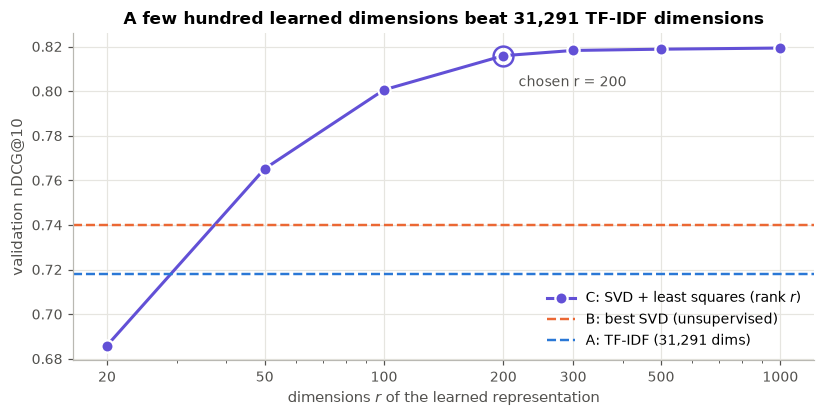

In [19]:
fig, ax = plt.subplots(figsize=(7.6, 3.9))
base_ndcg = val_scores["A: TF-IDF"].mean(axis=0)[4]
svd_ndcg = max(val_scores["B: SVD k=%d" % k].mean(axis=0)[4] for k in K_VALUES)
ax.plot(rank_tab.index, rank_tab["nDCG@10"], "o-", color=VIOLET, markeredgecolor="white", markeredgewidth=1.5,
        markersize=8, label="C: SVD + least squares (rank $r$)")
ax.axhline(svd_ndcg, color=ORANGE, lw=1.6, ls="--", label="B: best SVD (unsupervised)")
ax.axhline(base_ndcg, color=BLUE, lw=1.6, ls="--", label="A: TF-IDF (31,291 dims)")
ax.plot(R_SUP, rank_tab.loc[R_SUP, "nDCG@10"], "o", color=VIOLET, markersize=13, markerfacecolor="none", markeredgewidth=1.6)
ax.annotate("chosen r = %d" % R_SUP, (R_SUP, rank_tab.loc[R_SUP, "nDCG@10"]), textcoords="offset points",
            xytext=(10, -20), fontsize=9, color="#52514e")
ax.set_xscale("log"); ax.set_xticks(R_VALUES); ax.set_xticklabels(R_VALUES)
ax.set_xlabel("dimensions $r$ of the learned representation"); ax.set_ylabel("validation nDCG@10")
ax.set_title("A few hundred learned dimensions beat 31,291 TF-IDF dimensions")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Reading the output.**

- The result is insensitive to $\lambda$ over two orders of magnitude; only strong regularisation ($\lambda \ge 3$) hurts.
- More latent dimensions help the supervised map ($k=1000 > 500 > 300$): directions that are too weak to help
  *unsupervised* cosine similarity still carry topic information once least squares can weight them.
- The learned metric is **low-rank**: quality saturates at a few hundred dimensions. Two stacked SVDs
  (31,291 → 1000 → $r$) therefore give a representation that is roughly 100× smaller than TF-IDF *and* markedly more accurate.

## 11. Approach D — fusing the learned metric with exact term matching

The learned metric captures *topical* similarity; TF-IDF captures *exact vocabulary* overlap (specific method names,
datasets, acronyms). As in §9 the two are combined linearly,

$$ s_D = (1-\beta)\, s_C + \beta\, s_{\text{TF-IDF}}, $$

with $\beta$ chosen on the validation queries by nDCG@10.

**What the code does** — evaluates a grid of $\beta$ values and keeps the best.

In [20]:
def sim_fusion(beta):
    return lambda q: (1 - beta) * sim_C(q) + beta * sim_tfidf(q)

fus = pd.DataFrame([dict(summary(evaluate(sim_fusion(b), VAL)), beta=b) for b in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]]).set_index("beta")
BETA = float(fus["nDCG@10"].idxmax())
val_scores["D: fusion of C and A"] = evaluate(sim_fusion(BETA), VAL)
print("Fusion weight beta on TF-IDF (validation queries)"); display(fus[METRICS].round(4))
print("Chosen beta =", BETA)

Fusion weight beta on TF-IDF (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
beta,,,,,,,
0.0,0.8260,0.8047,0.0255,0.8876,0.8159,0.8547,0.9417
0.2,0.8282,0.8068,0.0267,0.8927,0.8184,0.8600,0.9450
0.3,0.8289,0.8074,0.0272,0.8949,0.8193,0.8630,0.9490
0.4,0.8286,0.8083,0.0280,0.8973,0.8205,0.8647,0.9510
0.5,0.8298,0.8079,0.0286,0.8987,0.8205,0.8640,0.9553
0.6,0.8287,0.8054,0.0289,0.8997,0.8184,0.8630,0.9583
0.7,0.8243,0.8010,0.0298,0.8978,0.8137,0.8573,0.9620


Chosen beta = 0.4


## 12. Deep-learning extension: pretrained transformer embeddings (Approaches E, F, G)

### 12.1 Why

Everything so far starts from a **bag of words**: the vector of a paper only records *which* stems occur. Two
sentences with the same meaning and different words are far apart until SVD or least squares pulls them together,
and word order is ignored altogether. A **transformer encoder** is a deep neural network that reads the text in
order and outputs one dense vector for the whole passage; it has been pretrained on hundreds of millions of text
pairs so that passages with similar meaning get similar vectors. We do **not** train any transformer here — we use
three published, pretrained encoders as fixed feature extractors:

| Key | Model | Output | Pretrained on |
|---|---|---:|---|
| `minilm` | `sentence-transformers/all-MiniLM-L6-v2` | 384 | 1 billion general sentence pairs |
| `specter` | `sentence-transformers/allenai-specter` | 768 | scientific papers (title + abstract), using citation links as the training signal |
| `bge` | `BAAI/bge-base-en-v1.5` | 768 | large-scale general retrieval pairs |

Each model maps `title + abstract` to a unit vector. None of them was trained on this corpus's topic labels.

### 12.2 The three new approaches

- **Approach E (unsupervised).** Concatenate the three unit embeddings and divide by $\sqrt 3$. The result
  $e \in \mathbb{R}^{1920}$ is again a unit vector and $e_q \cdot e_d$ equals the **mean of the three cosine
  similarities**. No labels are used.
- **Approach F (supervised).** Exactly the pipeline of Approach C — ridge least squares to topic space, then an SVD
  of the map — but on the richer feature vector $x = [\,s\,e^{(1)},\ s\,e^{(2)},\ s\,e^{(3)},\ z\,] \in \mathbb{R}^{2920}$
  (three embeddings scaled by $s$, plus the 1000-dimensional SVD vector $z$ of §6). The normal equations are now
  $2920 \times 2920$. Same pairwise-exclusion cross-fitting as §10.3.
- **Approach G.** Fusion of F and E: $s_G = (1-w)\,s_F + w\,s_E$.

The linear algebra is unchanged; only the input features are better. This also shows that SVD features and neural
features are complementary: F uses both.

### 12.3 Practical note — the embedding cache

Encoding 9,956 abstracts with three transformers takes about 4.5 minutes on a laptop GPU and needs the optional
packages `torch` and `sentence-transformers` plus a one-off download of the model weights. To keep the notebook fast
and runnable everywhere, the embeddings are stored in `data/paper_embeddings.npz` (35 MB, half precision). The cell
below **loads the cache if it exists and recomputes it otherwise**.

**What the code does**

- `get_encoder` / `encode` — lazily load a pretrained encoder and turn texts into unit vectors.
- Loads (or builds) the cache, checks that its paper ids match the corpus row by row, and builds `E_cat`.
- Evaluates each encoder alone and the combination on the validation queries.

In [21]:
EMB_MODELS = {                       # key: (Hugging Face model name, maximum number of tokens read)
    "minilm":  ("sentence-transformers/all-MiniLM-L6-v2", 256),
    "specter": ("sentence-transformers/allenai-specter",   384),
    "bge":     ("BAAI/bge-base-en-v1.5",                   384),
}
EMB_PATH = os.path.join(os.path.dirname(DATA_PATH), "paper_embeddings.npz")
_encoders = {}

def get_encoder(key):
    '''Load a pretrained encoder on first use (needs the optional packages torch and sentence-transformers).'''
    if key not in _encoders:
        import logging
        os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
        os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
        logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
        import torch, transformers
        from sentence_transformers import SentenceTransformer
        transformers.utils.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
        name, max_len = EMB_MODELS[key]
        device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
        try:                                                   # use the local model cache if the weights are there
            enc = SentenceTransformer(name, device=device, local_files_only=True)
        except Exception:                                      # first use: download the weights
            enc = SentenceTransformer(name, device=device)
        enc.max_seq_length = max_len
        _encoders[key] = enc
    return _encoders[key]

def encode(key, texts):
    '''texts -> unit-length embedding vectors, one row per text.'''
    out = get_encoder(key).encode(list(texts), batch_size=32, convert_to_numpy=True,
                                  normalize_embeddings=True, show_progress_bar=False)
    return out.astype(np.float32)

def paper_texts(key):
    sep = " [SEP] " if key == "specter" else ". "          # SPECTER was trained on "title [SEP] abstract"
    return (df["title"].fillna("") + sep + df["abstract"].fillna("")).tolist()

paper_ids = df["paper_id"].to_numpy(dtype=str)
if os.path.exists(EMB_PATH):
    cache = np.load(EMB_PATH, allow_pickle=False)
    assert (cache["paper_id"] == paper_ids).all(), "embedding cache does not match the corpus rows"
    print("Loaded cached embeddings:", EMB_PATH)
else:
    t0 = time.time()
    cache = {k: encode(k, paper_texts(k)).astype(np.float16) for k in EMB_MODELS}
    np.savez_compressed(EMB_PATH, paper_id=paper_ids, **cache)
    print("Computed and cached embeddings in %.0fs: %s" % (time.time() - t0, EMB_PATH))

EMB = {k: normalize(cache[k].astype(np.float32)) for k in EMB_MODELS}        # unit rows
E_cat = np.hstack([EMB[k] for k in EMB_MODELS]) / np.sqrt(len(EMB_MODELS))   # unit rows; dot = mean of 3 cosines
print("Embedding shapes:", {k: v.shape for k, v in EMB.items()}, " combined:", E_cat.shape)

def sim_E(q):                          # Approach E
    return E_cat[q] @ E_cat.T

rows = {"A: TF-IDF (for reference)": summary(val_scores["A: TF-IDF"]),
        "B+: hybrid (for reference)": summary(val_scores["B+: hybrid"])}
for k_ in EMB_MODELS:
    rows["%s alone" % k_] = summary(evaluate(lambda q: EMB[k_][q] @ EMB[k_].T, VAL))
val_scores["E: transformer embeddings"] = evaluate(sim_E, VAL)
rows["E: all three combined"] = summary(val_scores["E: transformer embeddings"])
print("Pretrained embeddings, no labels (validation queries)")
pd.DataFrame(rows).T[METRICS].round(4)

Loaded cached embeddings: ../data/paper_embeddings.npz
Embedding shapes: {'minilm': (9956, 384), 'specter': (9956, 768), 'bge': (9956, 768)}  combined: (9956, 1920)


Pretrained embeddings, no labels (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
A: TF-IDF (for reference),0.7365,0.6975,0.0292,0.8604,0.7181,0.7903,0.9710
B+: hybrid (for reference),0.7668,0.7259,0.0280,0.8777,0.7470,0.8227,0.9643
minilm alone,0.8636,0.8311,0.0350,0.9430,0.8491,0.9130,0.9893
specter alone,0.8489,0.8198,0.0334,0.9282,0.8363,0.8957,0.9820
bge alone,0.8716,0.8375,0.0366,0.9433,0.8555,0.9147,0.9900
E: all three combined,0.8872,0.8555,0.0381,0.9535,0.8720,0.9293,0.9910


**Reading the table.** Without seeing a single label, every pretrained encoder is far ahead of the best
bag-of-words method, and combining the three is better than any one of them. The deep models already "know" from
pretraining that, for example, *"intrusion detection"* and *"network attack classification"* belong together.

### 12.4 Approach F — least squares on embeddings + SVD features

**What the code does**

1. `features_F(s)` builds the 2,920-dimensional feature matrix.
2. The embedding scale $s$ and ridge strength $\lambda$ are tuned on the validation queries. Fitting 15
   pair-excluded models per setting would be slow, so tuning uses ordinary out-of-fold predictions
   (`oof_topic_vectors`, 5 models per setting) purely as a *selection* device — §13 confirms that the two protocols
   give nearly the same score.
3. With the chosen setting, the 15 pair-excluded models are fitted once and the rank $r$ is chosen by the same
   parsimony rule as in §10.4.

In [22]:
def features_F(s):
    '''[ s * embedding_1, s * embedding_2, s * embedding_3, SVD latent vector ]  ->  (m, 2920)'''
    return np.hstack([s * EMB[k] for k in EMB_MODELS] + [Z]).astype(np.float64)

t0 = time.time()
def tune_F(s_, lam):
    P_ = oof_topic_vectors(features_F(s_), lam)
    return dict(summary(evaluate(lambda q: P_[q] @ P_.T, VAL)), s=s_, lam=lam)

tune = [tune_F(s_, 1.0) for s_ in [1.0, 2.0, 4.0]]                           # 1. embedding scale s
S_F = float(max(tune, key=lambda r_: r_["nDCG@10"])["s"])
tune += [tune_F(S_F, lam) for lam in [0.3, 3.0, 10.0]]                             # 2. ridge strength lambda
tune = pd.DataFrame(tune).set_index(["s", "lam"])
LAMBDA_F = float(tune.loc[S_F, "nDCG@10"].idxmax())
print("Tuning by ordinary out-of-fold prediction (validation queries)"); display(tune[METRICS].round(4))
print("Chosen: s = %g, lambda = %g" % (S_F, LAMBDA_F))

X_F = features_F(S_F); X_F32 = X_F.astype(np.float32)
models_F = fit_all_pairs(LAMBDA_F, X=X_F, keep=1000)                         # the 15 pair-excluded models
rankF = pd.DataFrame([dict(summary(evaluate(make_sim_supervised(models_F, r, X=X_F32), VAL)), r=r)
                      for r in [50, 100, 200, 300, 500, 1000]]).set_index("r")
print("\nRank r of the learned metric, pairwise exclusion (validation queries)"); display(rankF[METRICS].round(4))
R_F = int(rankF.index[rankF["nDCG@10"] >= rankF["nDCG@10"].max() - 0.005][0])
print("Chosen rank r = %d      (tuning + fitting time: %.0fs)" % (R_F, time.time() - t0))

sim_F = make_sim_supervised(models_F, R_F, X=X_F32)
val_scores["F: embeddings + SVD + least squares"] = evaluate(sim_F, VAL)

Tuning by ordinary out-of-fold prediction (validation queries)


P@5    P@10    R@10     MRR  nDCG@10     P@1  Hit@10
s   lam                                                          
1.0 1.0   0.8989  0.8836  0.0358  0.9430   0.8926  0.9237  0.9760
2.0 1.0   0.9023  0.8856  0.0361  0.9435   0.8947  0.9253  0.9747
4.0 1.0   0.9012  0.8840  0.0364  0.9428   0.8936  0.9260  0.9743
2.0 0.3   0.8981  0.8825  0.0355  0.9389   0.8910  0.9203  0.9707
    3.0   0.9019  0.8857  0.0364  0.9450   0.8950  0.9267  0.9783
    10.0  0.9003  0.8791  0.0359  0.9500   0.8909  0.9330  0.9783

Chosen: s = 2, lambda = 3



Rank r of the learned metric, pairwise exclusion (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
r,,,,,,,
50,0.8216,0.8088,0.0210,0.8842,0.8173,0.8547,0.9410
100,0.8674,0.8516,0.0277,0.9249,0.8618,0.9010,0.9670
200,0.8924,0.8735,0.0331,0.9407,0.8840,0.9183,0.9763
300,0.8979,0.8794,0.0352,0.9453,0.8898,0.9240,0.9797
500,0.9012,0.8815,0.0365,0.9471,0.8923,0.9263,0.9787
1000,0.9030,0.8828,0.0370,0.9492,0.8939,0.9300,0.9793


Chosen rank r = 300      (tuning + fitting time: 37s)


### 12.5 Approach G — fusing F with the raw embeddings

As in §11, the learned metric (F) is combined with an unsupervised score — here the raw embedding similarity (E),
which is especially good at ranking the very first result. The weight $w$ is chosen on the validation queries.

In [23]:
def sim_G(w):
    return lambda q: (1 - w) * sim_F(q) + w * sim_E(q)

fusG = pd.DataFrame([dict(summary(evaluate(sim_G(w), VAL)), w=w) for w in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6]]).set_index("w")
W_G = float(fusG["nDCG@10"].idxmax())
val_scores["G: fusion of F and E"] = evaluate(sim_G(W_G), VAL)
print("Fusion weight w on the raw embeddings (validation queries)"); display(fusG[METRICS].round(4))
print("Chosen w =", W_G)

Fusion weight w on the raw embeddings (validation queries)


,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10
w,,,,,,,
0.0,0.8979,0.8794,0.0352,0.9453,0.8898,0.9240,0.9797
0.2,0.9020,0.8818,0.0361,0.9499,0.8931,0.9303,0.9807
0.3,0.9021,0.8834,0.0368,0.9519,0.8946,0.9327,0.9827
0.4,0.9037,0.8841,0.0374,0.9541,0.8957,0.9357,0.9847
0.5,0.9043,0.8837,0.0379,0.9553,0.8956,0.9370,0.9857
0.6,0.9054,0.8830,0.0385,0.9563,0.8954,0.9373,0.9880


Chosen w = 0.4


## 13. Final results on the held-out test queries  *(Objective 6)*

Every setting is now frozen: the TF-IDF configuration, the hybrid's $(k,\alpha)$, Approach C/D's
$(\lambda, r, \beta)$ and Approach F/G's $(s, \lambda, r, w)$ were all chosen on validation queries. The numbers below come from the **test queries, which
played no part in any choice**.

**What the code does**

- Evaluates every method on `TEST` and stores the per-query scores.
- `boot_ci` — percentile **bootstrap** 95% confidence interval for a mean (resample the queries with replacement 1,000 times).
- Builds the results table, then tests each method against the TF-IDF baseline with a **paired t-test** on per-query
  nDCG@10 (paired, because every method is scored on the same queries).

In [24]:
methods = {"A: TF-IDF (baseline)": (sim_tfidf, n)}
for k in K_VALUES:
    methods["B: SVD k=%d" % k] = (sim_svd(k), k)
methods["B+: hybrid (TF-IDF + SVD k=%d)" % K_HYB] = (sim_hybrid(K_HYB, ALPHA_HYB), n + K_HYB)
methods["C: SVD + least squares (r=%d)" % R_SUP] = (sim_C, R_SUP)
methods["D: fusion of C and A"] = (sim_fusion(BETA), n + R_SUP)
methods["E: transformer embeddings (unsupervised)"] = (sim_E, E_cat.shape[1])
methods["F: embeddings + SVD + least squares (r=%d)" % R_F] = (sim_F, R_F)
methods["G: fusion of F and E"] = (sim_G(W_G), R_F + E_cat.shape[1])

t0 = time.time()
test_scores = {name: evaluate(fn, TEST) for name, (fn, _) in methods.items()}
print("Evaluated %d methods on %d test queries in %.0fs" % (len(methods), len(TEST), time.time() - t0))

def boot_ci(x, B=1000, seed=SEED):
    '''Percentile bootstrap 95% CI for the mean of x.'''
    r_ = np.random.default_rng(seed); nq = len(x)
    means = np.array([x[r_.integers(0, nq, nq)].mean() for _ in range(B)])
    return np.percentile(means, [2.5, 97.5])

p_rand = N_REL[TEST] / (N - 1)                              # chance that one random paper is relevant, per query
rows = [dict(method="Random ranking (expected)", dims=np.nan, **{"P@5": p_rand.mean(), "P@10": p_rand.mean(),
                                                                 "P@1": p_rand.mean(),
                                                                 "Hit@10": (1 - (1 - p_rand) ** 10).mean()})]
for name, (_, dims) in methods.items():
    s = test_scores[name]; lo, hi = boot_ci(s[:, 4])
    rows.append(dict(method=name, dims=dims, **summary(s), **{"nDCG@10 95% CI": "[%.3f, %.3f]" % (lo, hi)}))
results = pd.DataFrame(rows).set_index("method")[["dims"] + METRICS + ["nDCG@10 95% CI"]]
results.style.format({**{c: "{:.4f}" for c in METRICS}, "dims": "{:,.0f}"}, na_rep="–") \
       .highlight_max(subset=METRICS, color="#d7e7fa")

Evaluated 13 methods on 6911 test queries in 11s


,dims,P@5,P@10,R@10,MRR,nDCG@10,P@1,Hit@10,nDCG@10 95% CI
method,,,,,,,,,
Random ranking (expected),–,0.0753,0.0753,–,–,–,0.0753,0.4805,–
A: TF-IDF (baseline),"31,291",0.7380,0.6990,0.0293,0.8633,0.7198,0.7954,0.9734,"[0.714, 0.726]"
B: SVD k=50,50,0.6886,0.6679,0.0168,0.7992,0.6801,0.7313,0.9200,"[0.672, 0.688]"
B: SVD k=100,100,0.7122,0.6869,0.0192,0.8213,0.7010,0.7558,0.9372,"[0.693, 0.708]"
B: SVD k=200,200,0.7313,0.7039,0.0217,0.8415,0.7196,0.7811,0.9479,"[0.712, 0.727]"
B: SVD k=300,300,0.7418,0.7115,0.0235,0.8542,0.7289,0.7953,0.9562,"[0.722, 0.736]"
B: SVD k=500,500,0.7538,0.7191,0.0263,0.8640,0.7378,0.8074,0.9608,"[0.731, 0.745]"
B: SVD k=1000,"1,000",0.7585,0.7206,0.0290,0.8745,0.7412,0.8177,0.9670,"[0.735, 0.748]"
B+: hybrid (TF-IDF + SVD k=300),"31,591",0.7637,0.7274,0.0280,0.8762,0.7472,0.8199,0.9680,"[0.741, 0.754]"


In [25]:
# ---- paired significance tests against the TF-IDF baseline (per-query nDCG@10 and P@10) ------------
base = test_scores["A: TF-IDF (baseline)"]
sig_rows = []
for name, s in test_scores.items():
    if name.startswith("A:"):
        continue
    d = s[:, 4] - base[:, 4]
    lo, hi = boot_ci(d)
    sig_rows.append({"method": name,
                     "Δ P@10": s[:, 1].mean() - base[:, 1].mean(),
                     "Δ MRR": s[:, 3].mean() - base[:, 3].mean(),
                     "Δ nDCG@10": d.mean(),
                     "95% CI of Δ nDCG@10": "[%+.3f, %+.3f]" % (lo, hi),
                     "paired t-test p (nDCG@10)": stats.ttest_rel(s[:, 4], base[:, 4]).pvalue,
                     "queries improved / worsened": "%d / %d" % ((d > 0).sum(), (d < 0).sum())})
sig = pd.DataFrame(sig_rows).set_index("method")
sig.style.format({"Δ P@10": "{:+.4f}", "Δ MRR": "{:+.4f}", "Δ nDCG@10": "{:+.4f}", "paired t-test p (nDCG@10)": lambda p: "below 1e-300" if p < 1e-300 else "%.1e" % p})

,Δ P@10,Δ MRR,Δ nDCG@10,95% CI of Δ nDCG@10,paired t-test p (nDCG@10),queries improved / worsened
method,,,,,,
B: SVD k=50,-0.0312,-0.0641,-0.0398,"[-0.046, -0.034]",2.5e-36,2639 / 3042
B: SVD k=100,-0.0121,-0.0421,-0.0188,"[-0.025, -0.014]",4.1e-11,2763 / 2755
B: SVD k=200,+0.0049,-0.0218,-0.0002,"[-0.005, +0.004]",9.3e-01,2884 / 2540
B: SVD k=300,+0.0124,-0.0092,+0.0090,"[+0.005, +0.013]",3.9e-05,2968 / 2372
B: SVD k=500,+0.0201,+0.0007,+0.0180,"[+0.014, +0.021]",9.0e-23,3038 / 2190
B: SVD k=1000,+0.0215,+0.0111,+0.0214,"[+0.019, +0.024]",6.0e-58,3089 / 2004
B+: hybrid (TF-IDF + SVD k=300),+0.0283,+0.0129,+0.0273,"[+0.025, +0.030]",4.7e-89,3170 / 1795
C: SVD + least squares (r=200),+0.1002,+0.0145,+0.0886,"[+0.083, +0.094]",1.7e-228,3882 / 1287
D: fusion of C and A,+0.1023,+0.0277,+0.0928,"[+0.088, +0.097]",1.4e-299,3965 / 1147


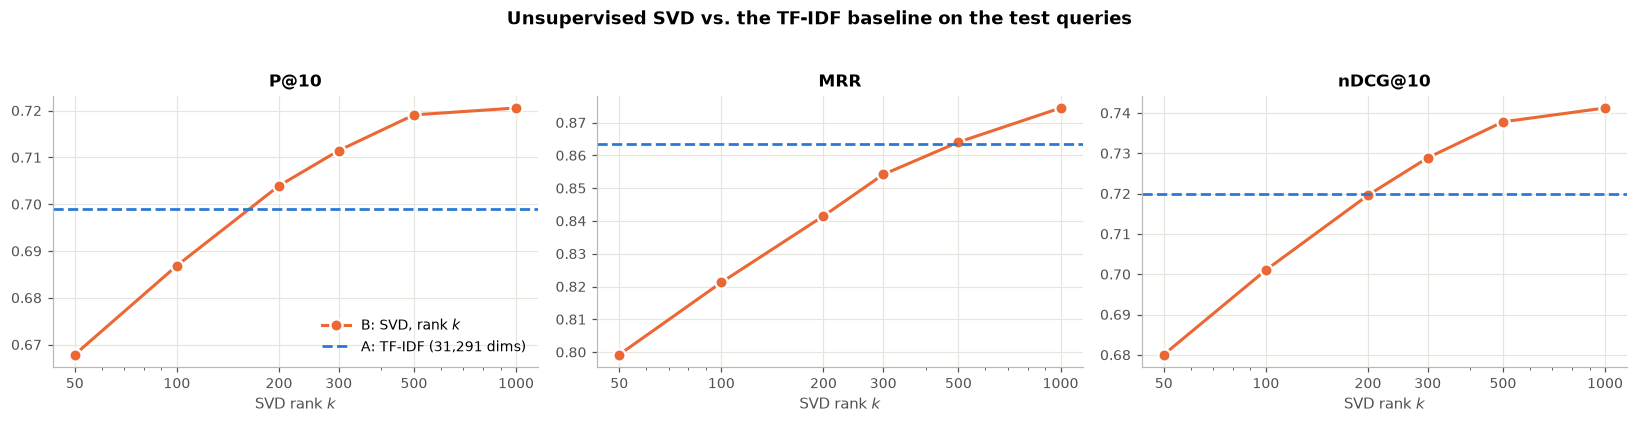

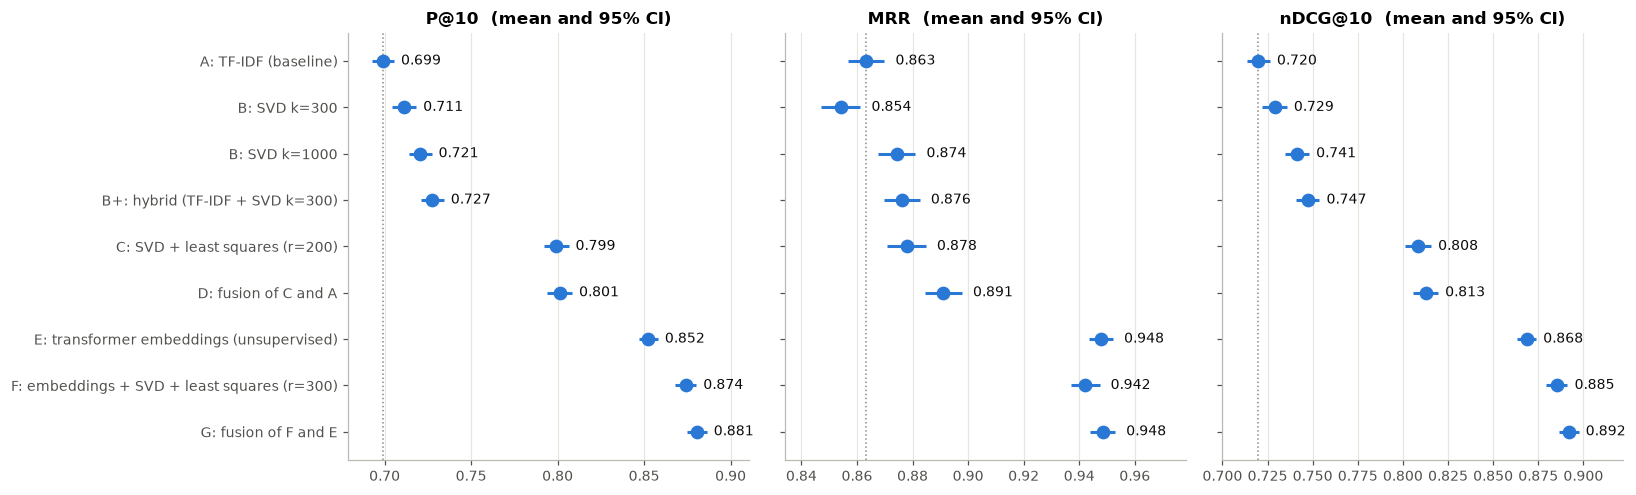

In [26]:
# ---- chart 1: SVD rank sweep against the TF-IDF baseline (test queries) -----------------------------
fig, ax = plt.subplots(1, 3, figsize=(15, 3.7), sharex=True)
for a, (mi, mname) in zip(ax, [(1, "P@10"), (3, "MRR"), (4, "nDCG@10")]):
    ys = [test_scores["B: SVD k=%d" % k][:, mi].mean() for k in K_VALUES]
    a.plot(K_VALUES, ys, "o-", color=ORANGE, markeredgecolor="white", markeredgewidth=1.5, markersize=8, label="B: SVD, rank $k$")
    a.axhline(base[:, mi].mean(), color=BLUE, lw=1.8, ls="--", label="A: TF-IDF (31,291 dims)")
    a.set_xscale("log"); a.set_xticks(K_VALUES); a.set_xticklabels(K_VALUES)
    a.set_title(mname); a.set_xlabel("SVD rank $k$")
ax[0].legend(loc="lower right")
fig.suptitle("Unsupervised SVD vs. the TF-IDF baseline on the test queries", y=1.03, fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.show()

# ---- chart 2: all approaches, with 95% bootstrap confidence intervals (dotted line = baseline) -----------
k_best_b = max(K_VALUES, key=lambda k: test_scores["B: SVD k=%d" % k][:, 4].mean())   # shown for reference only
show = ["A: TF-IDF (baseline)", "B: SVD k=300", "B: SVD k=%d" % (k_best_b if k_best_b != 300 else 1000),
        [m_ for m_ in methods if m_.startswith("B+")][0], [m_ for m_ in methods if m_.startswith("C:")][0], "D: fusion of C and A",
        "E: transformer embeddings (unsupervised)", [m_ for m_ in methods if m_.startswith("F:")][0], "G: fusion of F and E"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
ypos = np.arange(len(show))[::-1]
for a, (mi, mname) in zip(ax, [(1, "P@10"), (3, "MRR"), (4, "nDCG@10")]):
    means = np.array([test_scores[s_][:, mi].mean() for s_ in show])
    cis = np.array([boot_ci(test_scores[s_][:, mi]) for s_ in show])
    a.errorbar(means, ypos, xerr=[means - cis[:, 0], cis[:, 1] - means], fmt="o", color=BLUE, markersize=8,
               ecolor=BLUE, elinewidth=2, capsize=0)
    for y_, v, hi_ in zip(ypos, means, cis[:, 1]):
        a.text(hi_ + 0.004, y_, "%.3f" % v, va="center", fontsize=9, color="#0b0b0b")
    a.axvline(means[0], color=GREY, lw=1, ls=":")                         # the baseline, for reference
    a.set_xlim(means.min() - 0.02, means.max() + 0.03); a.set_ylim(-0.6, len(show) - 0.4)
    a.set_title(mname + "  (mean and 95% CI)"); a.grid(axis="y", visible=False)
ax[0].set_yticks(ypos); ax[0].set_yticklabels(show)
plt.tight_layout(); plt.show()

### Leakage audit for Approaches C and F

Because Approaches C and F learn from the same kind of labels that define relevance, their scores deserve an explicit check.
The cell below evaluates the **same method under three protocols** on the test queries:

| Protocol | Whose labels did the scoring model see? | Valid? |
|---|---|---|
| in-sample | both the query's and the candidate's | **no** — shown only to expose what leakage looks like |
| ordinary out-of-fold | not the paper's own, but the other paper's | optimistic in principle |
| **pairwise exclusion** *(reported)* | neither the query's nor the candidate's | **yes** |

If the reported protocol were leaking, it would score close to the in-sample figure. Ordinary out-of-fold vectors are
compared in the shared topic space $zW$ (each fold's model has its own $Q$ basis, so the low-rank coordinates of
different models are not comparable).

**What the code does** — for C and then for F: trains one map on all labelled papers (`L_all`, `L_F_all` — also the
deployment models used in §14 and §16), builds ordinary out-of-fold predictions, and evaluates all three variants on `TEST`.

In [27]:
# ---- (i) in-sample: one model trained on ALL labelled papers (this is also the deployment model) -------
t0 = time.time()
L_all = fit_metric(has_topic, LAMBDA)[:, :R_SUP]            # k x r learned projection
R_all = normalize(Z32 @ L_all)                               # every paper as a unit r-vector
sup_fit_time = time.time() - t0
s_insample = evaluate(lambda q: R_all[q] @ R_all.T, TEST)

# ---- (ii) ordinary out-of-fold: each paper predicted by a model that did not see that paper ------------
P_oof = oof_topic_vectors(Z, LAMBDA)
s_oof = evaluate(lambda q: P_oof[q] @ P_oof.T, TEST)
del P_oof

# ---- the same three protocols for Approach F (embeddings + SVD features) -------------------------------
t0 = time.time()
L_F_all = fit_metric(has_topic, LAMBDA_F, X=X_F)[:, :R_F]
R_F_all = normalize(X_F32 @ L_F_all)
supF_fit_time = time.time() - t0
sF_insample = evaluate(lambda q: R_F_all[q] @ R_F_all.T, TEST)
P_oof = oof_topic_vectors(X_F, LAMBDA_F)
sF_oof = evaluate(lambda q: P_oof[q] @ P_oof.T, TEST)
del P_oof

name_C = [m_ for m_ in methods if m_.startswith("C:")][0]
name_F = [m_ for m_ in methods if m_.startswith("F:")][0]
audit = pd.DataFrame({("C", "in-sample (invalid: labels of both papers seen)"): summary(s_insample),
                      ("C", "ordinary out-of-fold (full rank)"): summary(s_oof),
                      ("C", "pairwise exclusion, r=%d (reported)" % R_SUP): summary(test_scores[name_C]),
                      ("F", "in-sample (invalid: labels of both papers seen)"): summary(sF_insample),
                      ("F", "ordinary out-of-fold (full rank)"): summary(sF_oof),
                      ("F", "pairwise exclusion, r=%d (reported)" % R_F): summary(test_scores[name_F])}).T
audit.round(4)

P@5    P@10    R@10     MRR  nDCG@10     P@1  Hit@10
C in-sample (invalid: labels of both papers seen)  0.8853  0.8682  0.0328  0.9264   0.8765  0.9045  0.9628
  ordinary out-of-fold (full rank)                 0.8207  0.8033  0.0261  0.8794   0.8122  0.8443  0.9417
  pairwise exclusion, r=200 (reported)             0.8160  0.7992  0.0258  0.8778   0.8085  0.8413  0.9400
F in-sample (invalid: labels of both papers seen)  0.9545  0.9429  0.0457  0.9749   0.9492  0.9683  0.9873
  ordinary out-of-fold (full rank)                 0.8983  0.8804  0.0370  0.9397   0.8898  0.9195  0.9745
  pairwise exclusion, r=300 (reported)             0.8943  0.8741  0.0357  0.9420   0.8853  0.9224  0.9745

### How high can *any* text-based method go on this ground truth?

The ground truth is OpenAlex's automatic topic assignment, which is itself the output of a classifier and uses
information we do not have (for example the citation graph). If two papers with almost the same text are sometimes
given no topic in common, then no method that reads only title and abstract can be right about them. The cell below
measures this directly: for every pair of labelled papers, bucketed by how similar their texts are, **what fraction
shares a topic?**

**What the code does**

- `agreement_by_similarity` walks through all pairs (each once), buckets them by similarity under TF-IDF and under
  the transformer embeddings, and reports the pair count and the share of pairs that are "relevant" in each bucket.
- The second table groups the *test queries* by how close their 10th nearest neighbour is (a measure of how densely
  the corpus covers that query's subject) and shows Precision@10 in each group.

In [28]:
def agreement_by_similarity(sim_fn, edges):
    '''For all labelled pairs (i < j): number of pairs and fraction sharing a topic, per similarity bucket.'''
    cnt = np.zeros(len(edges) - 1); agree = np.zeros(len(edges) - 1)
    cols = np.arange(N)
    for s0 in range(0, N, 500):
        q = np.arange(s0, min(N, s0 + 500))
        Sm = np.asarray(sim_fn(q))
        valid = has_topic[q][:, None] & has_topic[None, :] & (q[:, None] < cols[None, :])
        b = np.digitize(Sm, edges) - 1
        for i in range(len(edges) - 1):
            mk = valid & (b == i)
            cnt[i] += mk.sum(); agree[i] += REL[q][mk].sum()
    return cnt.astype(int), agree / np.maximum(cnt, 1)

edges = [0.5, 0.6, 0.7, 0.8, 0.9, 1.01]
labels = ["0.5-0.6", "0.6-0.7", "0.7-0.8", "0.8-0.9", "0.9-1.0"]
c1, a1 = agreement_by_similarity(sim_tfidf, edges)
c2, a2 = agreement_by_similarity(sim_E, edges)
ceiling = pd.DataFrame({("TF-IDF cosine", "pairs"): c1, ("TF-IDF cosine", "share a topic"): a1,
                        ("embedding cosine (E)", "pairs"): c2, ("embedding cosine (E)", "share a topic"): a2},
                       index=pd.Index(labels, name="text similarity of the pair"))
display(ceiling.style.format({c_: "{:.3f}" for c_ in ceiling.columns if c_[1] == "share a topic"}))

# ---- per query: how close are the 10 nearest neighbours, and how precise is the best system there? -------
kth = np.concatenate([np.sort(np.where(np.arange(N)[None, :] == q[:, None], -1.0, sim_E(q)), axis=1)[:, -10]
                      for q in np.array_split(TEST, 14)])              # embedding cosine of the 10th nearest neighbour
bins = [-1, 0.6, 0.7, 0.8, 1.01]; names_ = ["below 0.6", "0.6-0.7", "0.7-0.8", "0.8 or more"]
grp = np.digitize(kth, bins) - 1
by_density = pd.DataFrame({"share of test queries": [np.mean(grp == i) for i in range(4)],
                           "A: TF-IDF  P@10": [test_scores["A: TF-IDF (baseline)"][grp == i, 1].mean() for i in range(4)],
                           "E: embeddings  P@10": [test_scores["E: transformer embeddings (unsupervised)"][grp == i, 1].mean() for i in range(4)],
                           "G: best system  P@10": [test_scores["G: fusion of F and E"][grp == i, 1].mean() for i in range(4)]},
                          index=pd.Index(names_, name="embedding cosine of the query's 10th nearest neighbour"))
by_density.round(3)

,share of test queries,A: TF-IDF P@10,E: embeddings P@10,G: best system P@10
embedding cosine of the query's 10th nearest neighbour,,,,
below 0.6,0.004,0.272,0.417,0.407
0.6-0.7,0.145,0.464,0.648,0.682
0.7-0.8,0.629,0.691,0.858,0.892
0.8 or more,0.222,0.884,0.978,0.987


### Reading the results

**Unsupervised SVD versus TF-IDF (the original research question).**

- Very small ranks lose information: $k=50$ and $k=100$ are significantly *worse* than TF-IDF on every metric.
- $k=200$ is statistically indistinguishable from TF-IDF on nDCG@10 (Δ = −0.0002, p = 0.93) with **156× fewer dimensions**.
- From $k=300$ SVD is significantly better on Precision@K and nDCG@10 (P@10 0.712 vs 0.699), but its MRR is still
  slightly lower (0.854 vs 0.863): TF-IDF's exact word matching is very good at getting the *first* result right.
- At $k=500$ MRR draws level and at $k=1000$ SVD is better on P@1, P@5, P@10, MRR and nDCG@10
  (P@10 0.721, MRR 0.875, nDCG@10 0.741 against 0.699, 0.863, 0.720).
- The hybrid B+ is better than both of its parts (nDCG@10 0.747), confirming that the two views are complementary.

> **Correction to the intermediate report.** With 400 queries the intermediate report concluded that SVD at $k=300$
> beat TF-IDF on all three metrics. With 6,911 test queries and confidence intervals the picture is more precise:
> $k=300$ wins on precision and nDCG but not on MRR; SVD is ahead on those metrics only from $k \approx 500$–$1000$.

**The supervised linear extension (C, D).**

- Approach C lifts Precision@10 from **0.699 to 0.799** and nDCG@10 from **0.720 to 0.809** with a
  **200-dimensional** representation; D adds exact term matching back (P@10 0.801, MRR 0.891).
- One honest caveat: C *lowers* Hit@10 (0.940 against 0.973 for TF-IDF). The learned metric concentrates on the
  dominant topics, so it returns more relevant papers on average but misses completely a little more often.

**The deep-learning extension (E, F, G).**

- **E — pretrained embeddings, no labels:** P@10 **0.852**, MRR **0.948**, Hit@10 **0.988**. Without using a single
  label it beats every bag-of-words system, including the label-trained D.
- **F — least squares on embeddings + SVD features:** P@10 **0.874**, nDCG@10 **0.885** in only **300 dimensions**.
- **G — fusion of F and E, the best system:** **P@1 0.929, P@5 0.902, P@10 0.881, MRR 0.948, nDCG@10 0.892,
  Hit@10 0.982.** Against the TF-IDF baseline it improves 4,690 test queries and worsens 509; Precision@10 is up by
  18 points.
- All differences from the baseline are far outside the confidence intervals (paired t-test p below 10⁻²²⁰ for C–G).

**Leakage audit.** For both supervised families the reported pairwise-exclusion score is essentially equal to the
ordinary out-of-fold score and far below the invalid in-sample score (C: 0.799 / 0.803 / 0.868; F: 0.874 / 0.880 /
0.943 on P@10). The reported gains are genuine generalisation from text to topics, not memorised labels.

**Why Precision@10 stops near 0.88 and not at 0.95.**

- The **only** configuration that reaches about 0.95 is the *in-sample* version of F (P@10 0.943) — the one that has
  seen the labels of the very papers it is scoring. That is over-fitting, and it is exactly what the evaluation
  protocol is designed to exclude.
- The two tables above show where the remaining errors come from. Pairs of papers whose embeddings are very close
  (cosine ≥ 0.8) share a topic 97–99% of the time, but at cosine 0.7–0.8 only 83% do, and at 0.6–0.7 only 49%.
  A query can only be answered with ten good papers if the corpus *contains* ten close papers: for the 22% of test
  queries whose 10th nearest neighbour is at cosine ≥ 0.8, system G reaches **P@10 = 0.987**; for the 63% in the
  0.7–0.8 band it reaches 0.892; for the 15% whose neighbourhood is sparse (below 0.7) it drops to about 0.68.
- The limiting factor is therefore the **coverage of a 10,000-paper corpus and the coarseness of an automatic
  topic label**, not the model. Where close neighbours exist the system is already about 99% precise.

**Why Recall@10 is tiny for every method.** A query has a median of about 800 relevant papers, so even a perfect
top-10 can retrieve at most ~1% of them. Precision@K, MRR, nDCG and Hit@10 are the informative metrics here; recall
is reported for completeness.

## 14. Efficiency: query time, dimensionality and storage  *(Objective 6)*

The second half of the research question is about **computational efficiency**. For each representation we measure

- **dimensions** of the vectors that are compared,
- **storage** of the document matrix in memory (sparse CSR for TF-IDF; dense `float32` otherwise),
- **query time**: the time to score one query paper against all 9,956 papers, averaged over 300 queries
  (single-threaded-style, one query at a time — the realistic online setting).

For Approaches C and F the timing uses the deployment models `R_all` and `R_F_all` built in §13 (one map trained on
all labelled papers); the cost is identical to that of any one of the cross-fitted models. For E, F and G the table
measures the *scoring* step; turning a brand-new text into a vector additionally requires one forward pass through
the three transformer encoders (tens of milliseconds on a laptop), whereas TF-IDF/SVD vectors cost well under a millisecond.

**What the code does** — `time_per_query` runs a scoring function over 300 queries three times and keeps the fastest
pass (less sensitive to background load); the table combines the timings with dimensions, storage and test nDCG@10.

In [29]:
def time_per_query(score_one, queries, repeats=3):
    best = np.inf
    for _ in range(repeats):                                 # best of 3 passes -> less timing noise
        t0 = time.perf_counter()
        for qi in queries:
            score_one(qi)
        best = min(best, time.perf_counter() - t0)
    return 1000 * best / len(queries)

bench_q = TEST[:300]
score_fns = {"A: TF-IDF (baseline)": lambda qi: (A @ A[qi].T).toarray().ravel()}
for k in K_VALUES:
    score_fns["B: SVD k=%d" % k] = (lambda V_: (lambda qi: V_ @ V_[qi]))(Zn[k])
score_fns[name_C] = lambda qi: R_all @ R_all[qi]
score_fns["D: fusion of C and A"] = lambda qi: (1 - BETA) * (R_all @ R_all[qi]) + BETA * (A @ A[qi].T).toarray().ravel()
score_fns["E: transformer embeddings (unsupervised)"] = lambda qi: E_cat @ E_cat[qi]
score_fns[name_F] = lambda qi: R_F_all @ R_F_all[qi]
score_fns["G: fusion of F and E"] = lambda qi: (1 - W_G) * (R_F_all @ R_F_all[qi]) + W_G * (E_cat @ E_cat[qi])

sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
eff = []
for name, fn in score_fns.items():
    dims = methods[name][1]
    if name.startswith("A:"):   store = sparse_mb
    elif name.startswith("D:"): store = sparse_mb + R_all.nbytes / 1e6
    elif name.startswith("C:"): store = R_all.nbytes / 1e6
    elif name.startswith("E:"): store = E_cat.nbytes / 1e6
    elif name.startswith("F:"): store = R_F_all.nbytes / 1e6
    elif name.startswith("G:"): store = (R_F_all.nbytes + E_cat.nbytes) / 1e6
    else:                       store = Zn[dims].nbytes / 1e6
    eff.append(dict(method=name, dims=dims, storage_MB=store, query_ms=time_per_query(fn, bench_q),
                    **{"nDCG@10": test_scores[name][:, 4].mean()}))
eff = pd.DataFrame(eff).set_index("method")
eff["speed-up vs A"] = eff.loc["A: TF-IDF (baseline)", "query_ms"] / eff["query_ms"]
print("One-off costs:  TF-IDF build %.1fs | rank-%d SVD %.1fs | least-squares map + second SVD: C %.1fs, F %.1fs"
      % (build_time_tfidf, K_MAX, svd_fit_time, sup_fit_time, supF_fit_time))
print("                Transformer embeddings of the corpus: about 4.5 minutes once on a laptop GPU (cached in data/).")
eff.style.format({"dims": "{:,}", "storage_MB": "{:.1f}", "query_ms": "{:.3f}", "nDCG@10": "{:.4f}", "speed-up vs A": "{:.1f}×"})

One-off costs:  TF-IDF build 0.7s | rank-1000 SVD 13.9s | least-squares map + second SVD: C 0.2s, F 1.1s
                Transformer embeddings of the corpus: about 4.5 minutes once on a laptop GPU (cached in data/).


,dims,storage_MB,query_ms,nDCG@10,speed-up vs A
method,,,,,
A: TF-IDF (baseline),"31,291",11.5,1.953,0.7198,1.0×
B: SVD k=50,50,2.0,0.018,0.6801,108.8×
B: SVD k=100,100,4.0,0.020,0.7010,95.9×
B: SVD k=200,200,8.0,0.023,0.7196,85.3×
B: SVD k=300,300,11.9,0.032,0.7289,60.2×
B: SVD k=500,500,19.9,0.054,0.7378,36.3×
B: SVD k=1000,"1,000",39.8,0.261,0.7412,7.5×
C: SVD + least squares (r=200),200,8.0,0.024,0.8085,82.5×
D: fusion of C and A,"31,491",19.5,2.118,0.8126,0.9×


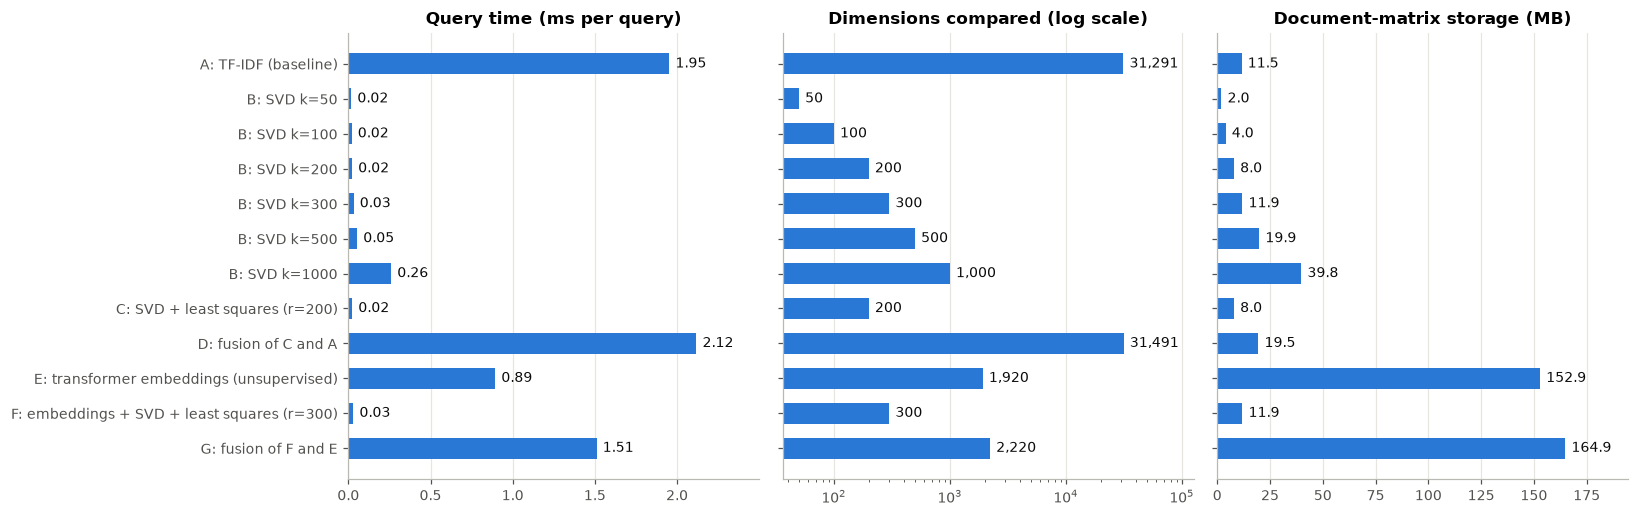

In [30]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
names = list(eff.index); ypos = np.arange(len(names))[::-1]
for a, col, title, fmt in [(ax[0], "query_ms", "Query time (ms per query)", "%.2f"),
                           (ax[1], "dims", "Dimensions compared (log scale)", "%d"),
                           (ax[2], "storage_MB", "Document-matrix storage (MB)", "%.1f")]:
    a.barh(ypos, eff[col], height=0.6, color=BLUE)
    if col == "dims": a.set_xscale("log")
    for y_, v in zip(ypos, eff[col]):
        a.annotate(("{:,}".format(int(v)) if col == "dims" else fmt % v), (v, y_), textcoords="offset points",
                   xytext=(4, 0), va="center", fontsize=9, color="#0b0b0b")
    a.set_title(title); a.grid(axis="y", visible=False)
    a.set_xlim(right=eff[col].max() * (4 if col == "dims" else 1.18))
ax[0].set_yticks(ypos); ax[0].set_yticklabels(names)
plt.tight_layout(); plt.show()

### Reading the efficiency results

(Timings depend on the machine and vary slightly between runs; dimensions and storage are exact.)

- **Query time.** Scoring in a dense space of a few hundred dimensions takes a few hundredths of a millisecond,
  against about 2 ms for the sparse 31,291-dimensional product — roughly **60–100× faster for 300 dimensions or
  fewer**, and still several times faster at $k=1000$.
- **Dimensions.** 31,291 → 200–1000, a 30–156× reduction.
- **Storage.** A dense `float32` matrix needs $m \times k \times 4$ bytes: 8 MB at 200 dimensions and 11.9 MB at
  300, about the same as the sparse TF-IDF matrix (11.5 MB); beyond that the dense matrix is larger.
- **Raw transformer embeddings are not cheap.** Approach E compares 1,920-dimensional dense vectors: 153 MB and
  about 1 ms per query — a 13× larger index than TF-IDF for a 2× speed-up.
- **Dimensionality reduction fixes that.** Approach F compresses the embeddings *and* the SVD vector into **300
  learned dimensions**: 11.9 MB and about 0.03 ms per query (≈ 60× faster than TF-IDF), with **higher** quality than
  the raw 1,920-dimensional embeddings (nDCG@10 0.885 against 0.869). This is the research question answered a
  second time, on neural features.
- **One-off costs.** The rank-1000 SVD takes about 14 s; each least-squares map and its SVD take about a second;
  encoding the corpus with three transformers takes about 4.5 minutes on a laptop GPU (done once and cached).
  Encoding a *new* free-text query with the transformers costs tens of milliseconds, against well under a
  millisecond for a TF-IDF/SVD vector.
- **Best trade-offs.** Without neural features: Approach C (200 dimensions, nDCG@10 0.809). With them: Approach F
  (300 dimensions, nDCG@10 0.885). Approach G buys the last 0.007 of nDCG@10 by keeping the full embedding matrix.

## 15. Visualising the latent space  *(Objective 7)*

A 2-D picture of a 1000-dimensional space is necessarily crude, but it shows whether the geometry reflects research
areas. Every paper is plotted at its coordinates along singular directions 2 and 3 (direction 1 is the corpus-wide
average, see §6.5). There is one panel per domain: that domain's papers in blue, all other papers in grey.

The `domain` column was never used by any model, so this is an independent check.

**What the code does** — draws six scatter plots of the same projection from a random sample of 4,000 papers.

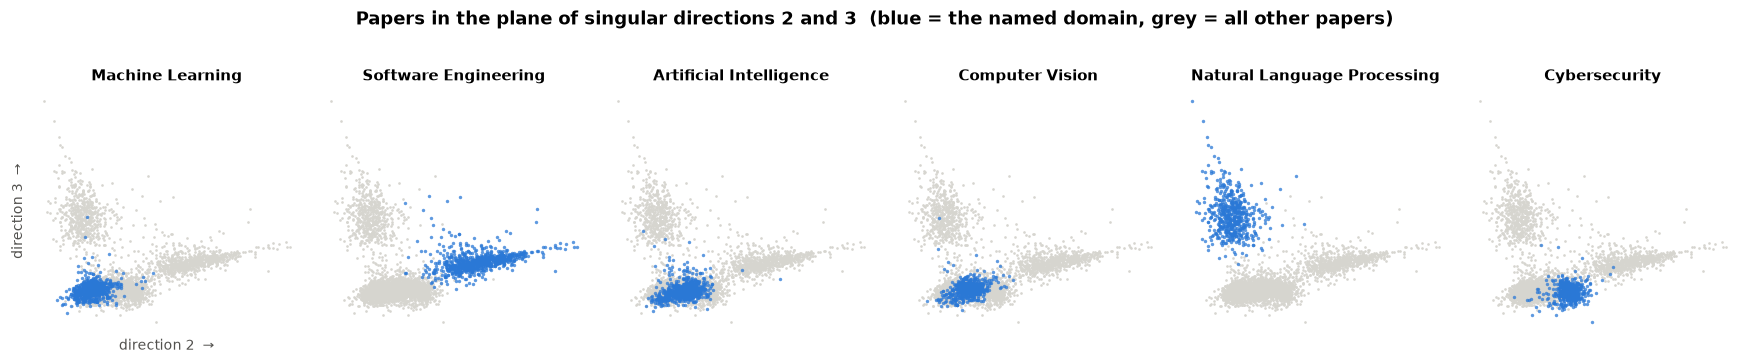

In [31]:
samp = np.random.default_rng(SEED).choice(N, 4000, replace=False)
domains = list(df["domain"].value_counts().index)
P2 = Z[samp, 1:3]                                            # coordinates along singular directions 2 and 3
dom_s = df["domain"].values[samp]

fig, axes = plt.subplots(1, len(domains), figsize=(16, 3.2), sharex=True, sharey=True)
for a, dom in zip(axes, domains):
    is_dom = dom_s == dom
    a.scatter(P2[~is_dom, 0], P2[~is_dom, 1], s=3, color="#d6d5cf", linewidths=0, rasterized=True)
    a.scatter(P2[is_dom, 0], P2[is_dom, 1], s=5, color=BLUE, alpha=0.75, linewidths=0, rasterized=True)
    a.set_xticks([]); a.set_yticks([]); a.grid(False); a.set_title(dom, fontsize=10)
    for sp_ in a.spines.values(): sp_.set_visible(False)
axes[0].set_ylabel("direction 3  →", fontsize=9); axes[0].set_xlabel("direction 2  →", fontsize=9)
fig.suptitle("Papers in the plane of singular directions 2 and 3  (blue = the named domain, grey = all other papers)",
             y=1.02, fontsize=11.5, fontweight="bold")
plt.tight_layout(); plt.show()

Each domain occupies its own region of the plane — Natural Language Processing, Software Engineering and
Cybersecurity separate cleanly, while Machine Learning, Artificial Intelligence and Computer Vision overlap, as
their vocabularies do — even though only two of the 1000 dimensions are visible and the domain label was never shown
to the model. The latent space captures genuine semantic structure, not noise.

## 16. Final model and interactive search  *(Objective 7)*

For actual use, one map is trained on **all** labelled papers (`L_all`, built in §14). A free-text query follows the
same path as a paper:

$$
\text{query text} \xrightarrow{\ \text{preprocess, TF-IDF}\ } q \in \mathbb{R}^{n}
\xrightarrow{\ \text{fold-in}\ z_q = qV_k\ } \mathbb{R}^{1000}
\xrightarrow{\ x_q = z_q L_r\ } \mathbb{R}^{r}
\xrightarrow{\ \text{cosine with every paper}\ } \text{ranking}.
$$

The full map $W$ additionally gives an interpretable by-product: $z_q W$ scores every topic for the query, so the
system can say *which topics it thinks the query is about*.

> These in-sample document vectors are used **only for the interactive demo**. Every number in §13 came from the
> pair-excluded models of §10.

**What the code does**

- Verifies the closed form of §10.2 ($W = (\Sigma^2 + \lambda I)^{-1}\Sigma U^{\mathsf T} Y$ when all rows are used).
- `predict_topics(query)` — top predicted topics for a text.
- `search(query, method, k)` — recommendations for a free-text query with approaches A–D.
- `embed_query_deep`, `search_deep(query, k)` — the same for Approach G: the query is encoded by the three
  transformers, combined with its SVD vector, projected with `L_F_all`, and fused with the raw embedding score.
  This is the only place where the encoders must be loaded; if `torch` / `sentence-transformers` are not installed
  the notebook falls back to Approach D.
- `recommend(idx, method, k)` — recommendations for a paper in the corpus (all vectors are stored, no encoder needed).

In [32]:
# ---- numerical check of the SVD closed form of ridge regression (all rows, so Z^T Z = Sigma^2) -------
G = Z.T @ Z
W_normal = sla.solve(G + LAMBDA * np.eye(K_MAX), Z.T @ Y, assume_a="pos")          # normal equations
W_svd = (sigma / (sigma ** 2 + LAMBDA))[:, None] * ((Z / sigma).T @ Y)             # (S^2 + lam I)^-1 S U^T Y
print("Z^T Z is diagonal (= Sigma^2):  max off-diagonal = %.1e,  max |diag - sigma^2| = %.1e"
      % (np.abs(G - np.diag(np.diag(G))).max(), np.abs(np.diag(G) - sigma ** 2).max()))
print("normal equations vs SVD closed form:  max |difference| = %.1e" % np.abs(W_normal - W_svd).max())

# W for topic prediction is trained on labelled papers only (unlabelled papers carry no information)
Xl = Z[has_topic]
W_all = sla.solve(Xl.T @ Xl + LAMBDA * np.eye(K_MAX), Xl.T @ Y[has_topic], assume_a="pos")

def embed_query(query):
    '''free text -> (TF-IDF row vector q, latent vector z_q = q V_k)'''
    q = vectorizer.transform([preprocess(query)])            # 1 x n sparse, unit length
    return q, svd.transform(q)                               # fold-in: z_q = q V_k   (1 x 1000)

def predict_topics(query, top=3):
    _, zq = embed_query(query)
    scores = (zq @ W_all).ravel()
    best = np.argsort(-scores)[:top]
    return [(topic_names[i], round(float(scores[i]), 3)) for i in best]

def search(query, method="fusion", k=5):
    '''Recommend papers for a free-text query.  method in {"tfidf", "svd", "supervised", "fusion"}.'''
    q, zq = embed_query(query)
    s_tfidf = (A @ q.T).toarray().ravel()                                    # Approach A
    if method == "tfidf":
        sims = s_tfidf
    elif method == "svd":
        sims = Zn[K_HYB] @ normalize(zq[:, :K_HYB]).ravel().astype(np.float32)   # Approach B
    else:
        s_sup = R_all @ normalize(zq.astype(np.float32) @ L_all).ravel()     # Approach C
        sims = s_sup if method == "supervised" else (1 - BETA) * s_sup + BETA * s_tfidf   # Approach D
    return result_table(sims, top_k(sims, k), cols=("title", "authors", "year", "domain"))

def embed_query_deep(query):
    '''free text -> (e_q: 1,920-d unit embedding vector,  x_q: r-dimensional learned vector of Approach F)'''
    _, zq = embed_query(query)
    parts = [encode(k_, [query]) for k_ in EMB_MODELS]                        # one forward pass per encoder
    e_q = np.hstack(parts).ravel() / np.sqrt(len(EMB_MODELS))
    x_q = np.hstack([S_F * p for p in parts] + [zq]).astype(np.float32)       # same feature layout as X_F
    return e_q, normalize(x_q @ L_F_all).ravel()

def search_deep(query, k=5):
    '''Approach G for a free-text query (needs torch + sentence-transformers to encode the query).'''
    e_q, x_q = embed_query_deep(query)
    sims = (1 - W_G) * (R_F_all @ x_q) + W_G * (E_cat @ e_q)
    return result_table(sims, top_k(sims, k), cols=("title", "authors", "year", "domain"))

def recommend(idx, method="deep", k=5):
    '''Recommend papers similar to corpus paper `idx` with the final models (no encoder needed: vectors are stored).'''
    s_tfidf = (A @ A[idx].T).toarray().ravel()
    s_sup = R_all @ R_all[idx]
    sims = {"tfidf": s_tfidf, "svd": Zn[K_HYB] @ Zn[K_HYB][idx], "supervised": s_sup,
            "fusion": (1 - BETA) * s_sup + BETA * s_tfidf,
            "deep": (1 - W_G) * (R_F_all @ R_F_all[idx]) + W_G * (E_cat @ E_cat[idx])}[method]
    sims = np.array(sims, dtype=np.float32); sims[idx] = -np.inf
    return result_table(sims, top_k(sims, k))

Z^T Z is diagonal (= Sigma^2):  max off-diagonal = 5.9e-13,  max |diag - sigma^2| = 1.3e-12
normal equations vs SVD closed form:  max |difference| = 1.4e-14


In [33]:
print("QUERY PAPER:", df["title"].iloc[seed], "   (final model, Approach G)\n")
display(recommend(seed, "deep", 5))

try:                                   # free-text queries for Approach G need the encoders (optional packages)
    for k_ in EMB_MODELS:
        get_encoder(k_)
    DEEP_OK = True
except Exception as e:
    DEEP_OK = False
    print("Transformer encoders unavailable (%s) - free-text search falls back to Approach D." % type(e).__name__)

for qtext in ["Graph neural networks for financial fraud detection",
              "transformer models for machine translation",
              "adversarial attacks on image classifiers"]:
    print("=" * 110)
    print("QUERY:", qtext, "   [%s]" % ("Approach G" if DEEP_OK else "Approach D"))
    print("Predicted topics:", "; ".join("%s (%.2f)" % t for t in predict_topics(qtext)))
    display(search_deep(qtext, k=5) if DEEP_OK else search(qtext, method="fusion", k=5))

QUERY PAPER: Machine learning and deep learning    (final model, Approach G)



,similarity,title,domain,year
0,0.799,Advances in Machine Learning and Deep Neural Networks,Machine Learning,2021.0
1,0.778,Artificial intelligence. Machine learning,Machine Learning,2019.0
2,0.770,Artificial intelligence and machine learning,Machine Learning,2022.0
3,0.769,"Artificial intelligence: a survey on evolution, models, applications and future trends",Artificial Intelligence,2019.0
4,0.768,Artificial intelligence within the interplay between natural and artificial computatio...,Artificial Intelligence,2020.0


QUERY: Graph neural networks for financial fraud detection    [Approach G]
Predicted topics: digital transformation in financial services (0.23); cybercrime and law enforcement studies (0.23); advanced graph neural networks (0.19)


,similarity,title,authors,year,domain
0,0.570,Detecting money laundering transactions with machine learning,Martin Jullum; Anders Løland; Ragnar Bang Huseby; Geir Ånonsen; Johannes Pippidis Lore...,2020.0,Machine Learning
1,0.543,Machine learning-driven credit risk: a systemic review,Si Shi; Rita T. Tse; Wuman Luo; Stefano d’Addona; Giovanni Pau,2022.0,Machine Learning
2,0.535,Machine Learning in Financial Crisis Prediction: A Survey,Wei-Yang Lin; Ya‐Han Hu; Chih‐Fong Tsai,2011.0,Machine Learning
3,0.518,Explainable Machine Learning in Credit Risk Management,Niklas Bussmann; Paolo Giudici; Dimitri Marinelli; Jochen Papenbrock,2020.0,Machine Learning
4,0.512,Fraud detection with natural language processing,Petros Boulieris; John Pavlopoulos; Alexandros Xenos; Vasilis Vassalos,2023.0,Natural Language Processing


QUERY: transformer models for machine translation    [Approach G]
Predicted topics: natural language processing techniques (0.55); topic modeling (0.49); translation studies and practices (0.27)


,similarity,title,authors,year,domain
0,0.841,Transformers in Natural Language Processing: A Comprehensive Review,Mohd Arsalan,2024.0,Natural Language Processing
1,0.816,Cantonese natural language processing in the transformers era: a survey and current ch...,Rong Xiang; Emmanuele Chersoni; Yixia Li; Jing Li; Chu‐Ren Huang; Yushan Pan; Yushi Li,2024.0,Natural Language Processing
2,0.800,Transformer Models in Natural Language Processing,Lea Lindberg,2021.0,Natural Language Processing
3,0.799,Example Based Machine Translation Using Natural Language Processing,Sunny Bhavan Sall; Sardar Vallabhbhai; Patel Polytechnic; R R Shedamkar; Dean Academic...,2013.0,Natural Language Processing
4,0.795,"Natural Language Processing, Deep Learning, and Text Processing: A Translational Persp...",Derya OĞUZ,2025.0,Natural Language Processing


QUERY: adversarial attacks on image classifiers    [Approach G]
Predicted topics: adversarial robustness in machine learning (1.17); security and verification in computing (0.49); digital media forensic detection (0.49)


,similarity,title,authors,year,domain
0,0.794,Threat of Adversarial Attacks on Deep Learning in Computer Vision: A Survey,Naveed Akhtar; Ajmal Saeed Mian,2018.0,Computer Vision
1,0.783,Adversarial Examples that Fool both Human and Computer Vision,Gamaleldin F. Elsayed; Shreya Shankar; Brian Cheung; Nicolas Papernot; Alexey Kurakin;...,2018.0,Computer Vision
2,0.781,Adversarial attacks on medical machine learning,Samuel G. Finlayson; John D. Bowers; Joichi Ito; Jonathan L. Zittrain; Andrew L. Beam;...,2019.0,Machine Learning
3,0.776,Adversarial machine learning for cybersecurity and computer vision: Current developmen...,Bowei Xi,2020.0,Computer Vision
4,0.772,Physical Adversarial Attack Meets Computer Vision: A Decade Survey,Hui Wei; Hao Tang; Xuemei Jia; Zhixiang Wang; Hanxun Yu; Zhubo Li; Shin’ichi Satoh; Lu...,2024.0,Computer Vision


### Live widget

Inside Jupyter the cell below shows a text box and a model selector. (In a static export such as HTML or PDF only the
initial result is visible.) The standalone Streamlit app `app.py` offers the same search in a browser:
`streamlit run app.py`.

In [34]:
try:
    import ipywidgets as W_
    from IPython.display import display as _show, clear_output
    box = W_.Text(value="Graph neural networks for fraud detection", description="Query:", layout=W_.Layout(width="60%"))
    options = [("D: fusion of C and A", "fusion"), ("C: SVD + least squares", "supervised"), ("B: SVD", "svd"), ("A: TF-IDF", "tfidf")]
    if DEEP_OK:
        options.insert(0, ("G: deep fusion (best)", "deep"))
    model = W_.Dropdown(options=options, value=options[0][1], description="Model:")
    out = W_.Output()
    def _run(_=None):
        with out:
            clear_output()
            print("Predicted topics:", "; ".join("%s (%.2f)" % t for t in predict_topics(box.value)))
            _show(search_deep(box.value, k=8) if model.value == "deep" else search(box.value, method=model.value, k=8))
    box.on_submit(_run); model.observe(_run, "value")
    _run()
    _show(W_.VBox([W_.HBox([box, model]), out]))
except Exception as e:
    print("Widget unavailable (%s) - call search('your query') directly." % type(e).__name__)

## 17. Conclusion

**Research question.** *Does linear-algebraic dimensionality reduction using SVD improve the effectiveness and
computational efficiency of research-paper recommendation compared with the original TF-IDF representation?*

**Answer: yes — on efficiency clearly, on effectiveness modestly by itself and substantially when combined with
least squares, and the same holds when the input features are neural embeddings.** All figures are means over 6,911
held-out test queries.

| Representation | Dimensions | P@1 | P@10 | MRR | nDCG@10 | Hit@10 | Query time vs TF-IDF |
|---|---:|---:|---:|---:|---:|---:|---|
| A — TF-IDF (baseline) | 31,291 | 0.795 | 0.699 | 0.863 | 0.720 | 0.973 | 1× |
| B — SVD, $k=300$ | 300 | 0.795 | 0.712 | 0.854 | 0.729 | 0.956 | ≈ 60× faster |
| B — SVD, $k=1000$ | 1,000 | 0.818 | 0.721 | 0.875 | 0.741 | 0.967 | ≈ 7× faster |
| B+ — hybrid of A and B | 31,591 | 0.820 | 0.727 | 0.876 | 0.747 | 0.968 | ≈ 1× |
| C — SVD + least-squares metric | 200 | 0.841 | 0.799 | 0.878 | 0.809 | 0.940 | ≈ 80× faster |
| D — fusion of C and A | 31,491 | 0.855 | 0.801 | 0.891 | 0.813 | 0.954 | ≈ 1× |
| E — transformer embeddings (no labels) | 1,920 | 0.923 | 0.852 | 0.948 | 0.869 | **0.988** | ≈ 2× faster |
| **F — embeddings + SVD + least squares** | **300** | 0.922 | 0.874 | 0.942 | 0.885 | 0.975 | **≈ 60× faster** |
| **G — fusion of F and E** | 2,220 | **0.929** | **0.881** | **0.948** | **0.892** | 0.982 | ≈ 2× faster |

1. **Efficiency.** SVD reduces 31,291 sparse dimensions to a few hundred dense ones and makes a query one to two
   orders of magnitude faster. This holds for every $k$ tested.
2. **Effectiveness, unsupervised.** Rank $k=200$ already matches TF-IDF on nDCG@10; $k \ge 300$ is significantly
   better on precision and nDCG, and $k = 1000$ is better on P@K, MRR and nDCG. The gain is real but small (about two
   points), and very low ranks ($k \le 100$) are worse than the baseline — the trade-off between information loss and
   noise removal that the theory predicts.
3. **Effectiveness, with least squares.** Learning a linear map on top of the SVD space and compressing it with a
   second SVD gives a 200-dimensional representation that is **ten points more precise than TF-IDF and about 80×
   faster to query**. The $1000 \times 1000$ normal equations that make this possible exist only *because* of the
   dimensionality reduction; in the raw space the system would be $31{,}291 \times 31{,}291$.
4. **With deep-learning features.** Pretrained transformer embeddings are much stronger inputs than bags of words
   (P@10 0.852 with no labels). Feeding them, together with the SVD vector, through the *same* least-squares + SVD
   pipeline gives the best system: **P@10 0.881, P@1 0.929, MRR 0.948, Hit@10 0.982**, and a 300-dimensional
   variant (F) that is both more accurate and 6× smaller than the raw embeddings.
5. **About 95%.** Precision@10 of 0.95 was reached only by the in-sample (label-leaking) variant, which is
   over-fitting. Honest evaluation tops out at 0.88 because many queries simply do not have ten close neighbours in
   a 10,000-paper corpus (§13). Metrics that ask an easier question are above 0.95 honestly: the top
   recommendation is relevant 92.9% of the time (P@1), the first relevant paper appears on average at rank
   1/0.948 ≈ 1.05 (MRR), and **98.2% of queries get at least one relevant paper in the top 10 (Hit@10)**.
6. **The mathematics behaves as stated.** Orthonormality, the projection identity, Eckart–Young, the Gram identity
   and the SVD closed form of ridge regression were all verified numerically to round-off precision (§3, §6.3, §16).

### What was added for the final submission

- Evaluation on **all** ≈9,900 queries with a **validation/test split**, bootstrap confidence intervals, paired
  significance tests, nDCG@10, P@1, Hit@10 and a random baseline (previously: 400 queries, no split, no uncertainty).
- A worked **toy example** with the SVD computed by hand from an eigen-decomposition.
- **Numerical verification** of every linear-algebra identity used.
- SVD rank sweep extended to $k = 1000$, and **interpretation** of the latent directions.
- New approaches: the **hybrid** (B+), the **least-squares learned metric** (C), its **fusion** (D), and the
  **deep-learning extension** (E, F, G) — with a strict leakage-free protocol, an explicit leakage audit and an
  analysis of what limits precision.
- Predicted topics for free-text queries, and transformer-based free-text search, in the interface.

### Limitations

- **Proxy ground truth.** "Shares an OpenAlex topic" is an automatic label, not a human relevance judgement; topics
  are broad (a query has hundreds of relevant papers), so the metrics measure topical agreement rather than
  usefulness to a reader.
- **Approaches C, D, F and G need labels.** They require a corpus in which most papers carry topic labels and they
  optimise agreement with that label scheme. A, B, B+ and E need no labels.
- **Pretrained encoders are external knowledge.** The transformers were trained by others on very large text
  collections (SPECTER on scientific papers and their citation links). They were never trained on this corpus's
  topic labels, but they may have seen some of these abstracts as plain text; this is standard practice for
  pretrained models and is the reason E, F and G are reported separately from the purely linear-algebraic A–D.
  They are also far heavier: about 1 GB of model weights, a GPU-friendly encoding step, and a 153 MB index for E.
- **Bag of words (A–D).** Word order and context are ignored; this is what the embeddings of E–G add.
- **Corpus.** One corpus of 9,956 computer-science papers; about 100 papers share an abstract with another paper
  (kept as collected). Timings are for exhaustive scoring on one machine.
- **Tuning.** All hyper-parameters were chosen on validation queries from the same corpus; the test queries were
  not used for any choice.

## Appendix A — Code map

| Name | Defined in | Purpose |
|---|---|---|
| `preprocess(text)` | §2 | lower-case, tokenise, remove stop-words, stem |
| `vectorizer`, `A`, `A_T`, `terms` | §4 | TF-IDF model, term–document matrix (CSR), its transpose, vocabulary |
| `top_k`, `result_table` | §5 | top-$k$ selection; formatting of a result list |
| `recommend_tfidf(idx, k)` | §5 | Approach A for a corpus paper |
| `svd`, `Z`, `sigma`, `Vt`, `Zn[k]` | §6 | rank-1000 SVD model, latent matrix $U\Sigma$, singular values, $V^{\mathsf T}$, row-normalised rank-$k$ latent matrices |
| `recommend_svd(idx, k_dim, k)` | §7 | Approach B for a corpus paper |
| `T`, `REL`, `N_REL`, `VAL`, `TEST` | §8 | topic incidence matrix, relevance matrix, #relevant per query, query splits |
| `evaluate(sim_fn, queries)` | §8 | per-query P@5, P@10, R@10, RR, nDCG@10, P@1, Hit@10 for any similarity function |
| `sim_tfidf`, `sim_svd(k)`, `sim_hybrid(k, α)` | §8 | similarity functions for A, B, B+ |
| `fit_metric(mask, λ, k)` | §10 | ridge least squares + SVD of $W$ → learned projection $L$ |
| `fit_all_pairs(λ, k)` | §10 | the 15 pair-excluded models |
| `make_sim_supervised(models, r)` | §10 | leakage-free similarity function for Approach C |
| `sim_fusion(β)` | §11 | similarity function for Approach D |
| `boot_ci(x)` | §13 | bootstrap 95% confidence interval of a mean |
| `get_encoder`, `encode`, `EMB`, `E_cat`, `sim_E` | §12 | pretrained transformer encoders, cached embeddings, Approach E |
| `features_F`, `oof_topic_vectors`, `models_F`, `sim_F`, `sim_G(w)` | §10, §12 | feature matrix, tuning helper, pair-excluded models and similarity functions for F and G |
| `L_all`, `R_all`, `W_all`, `L_F_all`, `R_F_all` | §13, §16 | final projections, final document vectors, final topic map |
| `agreement_by_similarity` | §13 | label-noise ceiling analysis |
| `embed_query`, `predict_topics`, `search`, `embed_query_deep`, `search_deep`, `recommend` | §16 | free-text and paper-based recommendation with the final models |

## Appendix B — Questions an examiner might ask

**1. Why cosine similarity and not Euclidean distance?**
Cosine depends only on direction, not length, so a long abstract and a short abstract on the same subject are close.
For unit vectors the two are equivalent anyway: $\lVert x-y\rVert^2 = 2 - 2\cos(x,y)$.

**2. Why is the TF-IDF matrix stored sparsely?**
Only about 0.3% of its entries are non-zero. Dense storage would need $9956 \times 31291 \times 8$ bytes ≈ 2.5 GB; CSR
needs about 12 MB, and a matrix–vector product costs time proportional to the number of non-zeros.

**3. What exactly does SVD do to the data?**
It rotates the term axes to new orthogonal axes ordered by how much of the matrix's energy they carry
($\sigma_1^2 \ge \sigma_2^2 \ge \dots$) and keeps the first $k$. Geometrically each document is orthogonally projected
onto the $k$-dimensional subspace that loses the least squared length (Eckart–Young).

**4. How is SVD related to eigen-decomposition and to PCA?**
$A^{\mathsf T}A = V\Sigma^2V^{\mathsf T}$ and $AA^{\mathsf T} = U\Sigma^2U^{\mathsf T}$: the singular vectors are eigenvectors of
these symmetric matrices (shown by hand in §3). PCA is the SVD of the *column-centred* matrix; LSA skips the centring
to keep the matrix sparse.

**5. Why can a smaller representation be *better* than the original?**
Truncation removes directions dominated by paper-specific word choice (noise) and merges co-occurring terms
(synonyms), so papers that use different words for the same idea move closer — the toy example in §3 shows a cosine
going from 0 to nearly 1.

**6. Why does explained energy stay low even at $k=1000$, and is that a problem?**
TF-IDF spectra decay slowly because most terms are rare. The discarded part is mostly document-specific noise; the
evaluation shows retrieval quality is preserved or improved, which is what matters.

**7. How is a new query handled without recomputing the SVD?**
Fold-in: $z_q = q V_k$, a single sparse-vector × matrix product (`svd.transform`).

**8. What are the normal equations and why add $\lambda I$?**
Minimising $\lVert ZW-Y\rVert_F^2$ gives $Z^{\mathsf T}ZW = Z^{\mathsf T}Y$. Adding $\lambda\lVert W\rVert_F^2$ gives
$(Z^{\mathsf T}Z+\lambda I)W = Z^{\mathsf T}Y$; the matrix becomes strictly positive definite (unique solution, stable
Cholesky) and weak directions are shrunk by $\sigma_i^2/(\sigma_i^2+\lambda)$, which limits over-fitting.

**9. Approaches C and F use the topic labels, and the evaluation uses the topic labels. Is that cheating?**
It would be if a paper's own labels influenced its score. They never do: the model that compares a query and a
candidate was trained without either paper's fold (§10.3). The method therefore has to *generalise* from text to
topics, exactly as it would for a brand-new unlabelled paper; the leakage audit in §13 quantifies the difference.
Approaches A, B, B+ and E use no labels at all and are reported separately so that the two families are never confused.

**10. Why split queries into validation and test?**
Picking the best of many settings on a set of queries and then reporting that same score overstates performance
(selection bias). Settings are picked on validation queries; the test queries give an unbiased estimate.

**11. What does the confidence interval / p-value tell us?**
The interval is the range in which the mean metric would fall if the experiment were repeated on another sample of
queries. The paired t-test asks whether the mean per-query difference from the baseline could be zero; a tiny p-value
means the difference is not a sampling accident.

**12. What is the time complexity of a query?**
TF-IDF: proportional to the non-zeros touched by the query's terms. SVD or learned metric: $O(m\,k)$ dense
multiplications ($m$ = papers, $k$ = dimensions), which is cache-friendly and trivially parallel. For much larger
corpora the dense vectors can be indexed with approximate nearest-neighbour structures, which is not possible for
31,000-dimensional sparse vectors.

**13. What are the main limitations?**
See §17: proxy ground truth, a single corpus, supervised extensions that need labelled papers, and pretrained encoders that bring in external knowledge.

**14. What is a transformer embedding, and why is it better than TF-IDF?**
A transformer is a deep neural network that reads the tokens of a passage in order and lets every token attend to
every other one; the final token representations are averaged into one dense vector. Pretraining on hundreds of
millions of related text pairs teaches it to place passages with similar *meaning* close together, so synonyms,
paraphrases and word order are handled before any linear algebra is applied. TF-IDF only knows which stems occur.

**15. If deep embeddings are so good, why keep SVD and least squares?**
Three reasons shown in §12–§14: the least-squares map still adds two points of precision on top of the embeddings;
the SVD features are complementary (F uses both); and reducing 1,920 dimensions to 300 makes the index 13× smaller
and queries about 30× faster *while improving* accuracy.

**16. Why is Precision@10 "only" 0.88? Could it be pushed to 0.95?**
Only by letting the model see the labels of the papers it is scoring (the in-sample variant reaches 0.943), which
is over-fitting. With a leakage-free protocol the errors come from queries whose subject is thinly covered: when a
query's ten nearest papers are all very close (22% of queries) precision is 0.987; when they are not, a tenth
"nearest" paper is often about a neighbouring subject. A larger corpus or human relevance labels would raise the
number; a cleverer model on this corpus would mostly not.

**17. Which single number should be quoted?**
State the metric with it. Precision@10 = 0.881 (average share of relevant papers in the top 10); P@1 = 0.929;
MRR = 0.948; Hit@10 = 0.982 (share of queries with at least one relevant paper in the top 10). They answer
different questions and should not be presented as one "accuracy".